# 03 - Data quality: child tables (feature by feature)

Quality checks and cleaning for bureau, previous applications, installments,
POS cash, and credit card tables. Same discipline as notebook 02: inspect,
visualize, clean dirty fields, show before/after.

Large tables are handled **one table at a time** with chunked scans where needed.
Restart the kernel before running if RAM is tight.

Leakage reminder: relative day/month offsets that are after application time
must not feed application-time features (enforced later in SQL + tests).

In [1]:
from __future__ import annotations

import gc
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DAYS_EMPLOYED_ANOMALY, PROCESSED_DATA_DIR, RAW_DATA_DIR

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
DECISIONS: list[dict] = []
CHUNKSIZE = 500_000
SAMPLE_N = 80_000
DAY_SENTINEL = DAYS_EMPLOYED_ANOMALY  # 365243 used across Home Credit tables

print(PROJECT_ROOT)
print("day sentinel:", DAY_SENTINEL)

C:\Users\user\Desktop\Credit-Scoring Project
day sentinel: 365243


In [2]:
def record(table: str, feature: str, issue: str, action: str, detail: str = "") -> None:
    DECISIONS.append(
        {
            "table": table,
            "feature": feature,
            "issue": issue,
            "action": action,
            "detail": detail,
        }
    )
    print(f"[decision] {table}.{feature}: {action} ({issue})")


def plot_numeric(series: pd.Series, title: str, bins: int = 50, ax=None):
    ax = ax or plt.gca()
    sns.histplot(series.dropna(), bins=bins, kde=False, ax=ax, color="steelblue")
    ax.set_title(title)
    ax.set_xlabel(series.name)
    return ax


def plot_categorical(series: pd.Series, title: str, top_n: int | None = 15, figsize=(8, 4)):
    counts = series.fillna("__MISSING__").value_counts()
    if top_n is not None:
        counts = counts.head(top_n)
    fig, ax = plt.subplots(figsize=figsize)
    sns.barplot(x=counts.values, y=counts.index.astype(str), ax=ax, color="teal")
    ax.set_title(title)
    ax.set_xlabel("count")
    plt.tight_layout()
    plt.show()
    return counts


def before_after_numeric(before: pd.Series, after: pd.Series, title_b: str, title_a: str, bins: int = 50):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    plot_numeric(before, title_b, bins=bins, ax=axes[0])
    plot_numeric(after, title_a, bins=bins, ax=axes[1])
    plt.tight_layout()
    plt.show()


def feature_report(df: pd.DataFrame, col: str, table: str = "") -> None:
    s = df[col]
    prefix = f"{table}." if table else ""
    print(f"\n=== {prefix}{col} ===")
    print(f"dtype={s.dtype}  missing={s.isna().sum():,} ({100 * s.isna().mean():.2f}%)")
    print(f"n_unique={s.nunique(dropna=True)}")
    if pd.api.types.is_numeric_dtype(s):
        display(s.describe())
    else:
        display(s.value_counts(dropna=False).head(12))


def replace_day_sentinel(s: pd.Series, sentinel: int = DAY_SENTINEL) -> tuple[pd.Series, pd.Series]:
    """Return cleaned series and anomaly flag."""
    flag = (s == sentinel).astype("int8")
    out = s.mask(s == sentinel, np.nan)
    return out, flag


def sample_csv(path: Path, n: int = SAMPLE_N, usecols=None) -> pd.DataFrame:
    """Reservoir-style approx sample via first chunks shuffled (good enough for viz)."""
    parts = []
    taken = 0
    for chunk in pd.read_csv(path, usecols=usecols, chunksize=CHUNKSIZE, low_memory=False):
        need = n - taken
        if need <= 0:
            break
        if len(chunk) <= need:
            parts.append(chunk)
            taken += len(chunk)
        else:
            parts.append(chunk.sample(need, random_state=42))
            taken += need
            break
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


def chunked_value_counts(path: Path, col: str, top_n: int = 20) -> pd.Series:
    counts: dict[object, int] = {}
    for chunk in pd.read_csv(path, usecols=[col], chunksize=CHUNKSIZE, low_memory=False):
        vc = chunk[col].fillna("__MISSING__").value_counts()
        for k, v in vc.items():
            counts[k] = counts.get(k, 0) + int(v)
        del chunk
    s = pd.Series(counts).sort_values(ascending=False)
    return s.head(top_n)


def chunked_null_and_sentinel(path: Path, col: str, sentinel: int = DAY_SENTINEL) -> dict:
    n = 0
    n_null = 0
    n_sent = 0
    for chunk in pd.read_csv(path, usecols=[col], chunksize=CHUNKSIZE, low_memory=False):
        n += len(chunk)
        n_null += int(chunk[col].isna().sum())
        n_sent += int((chunk[col] == sentinel).sum())
        del chunk
    return {"rows": n, "null": n_null, "sentinel": n_sent}

---
# A. `bureau.csv`

External credit history. One row per bureau credit (`SK_ID_BUREAU`).

shape: (1716428, 17)
memory_mb: 512.1


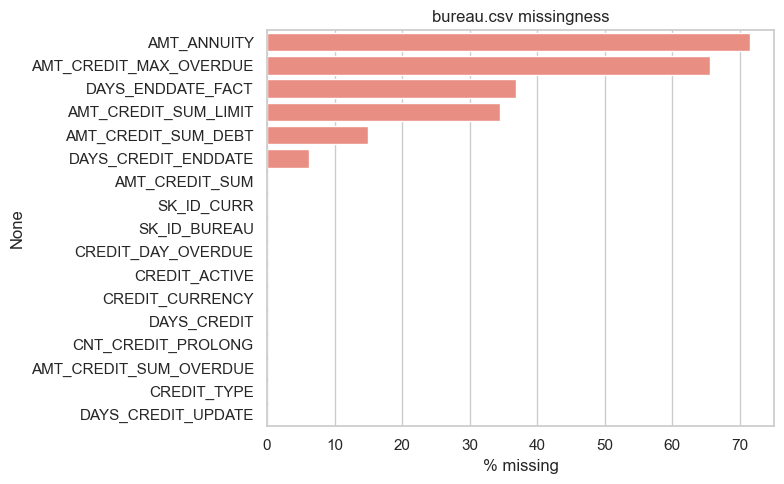

In [3]:
bureau_path = RAW_DATA_DIR / "bureau.csv"
bureau = pd.read_csv(bureau_path, low_memory=False)
print("shape:", bureau.shape)
print("memory_mb:", round(bureau.memory_usage(deep=True).sum() / 1024**2, 1))

miss = (bureau.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=miss.values, y=miss.index, ax=ax, color="salmon")
ax.set_xlabel("% missing")
ax.set_title("bureau.csv missingness")
plt.tight_layout()
plt.show()

## Feature: `SK_ID_CURR` / `SK_ID_BUREAU`

In [4]:
assert bureau["SK_ID_BUREAU"].isna().sum() == 0
assert bureau["SK_ID_CURR"].isna().sum() == 0
print("duplicate SK_ID_BUREAU:", int(bureau["SK_ID_BUREAU"].duplicated().sum()))
print("unique SK_ID_CURR:", bureau["SK_ID_CURR"].nunique())
record("bureau", "SK_ID_BUREAU", "none", "keep; unique bureau credit id")
record("bureau", "SK_ID_CURR", "none", "keep; join key to application")

duplicate SK_ID_BUREAU: 0
unique SK_ID_CURR: 305811
[decision] bureau.SK_ID_BUREAU: keep; unique bureau credit id (none)
[decision] bureau.SK_ID_CURR: keep; join key to application (none)


## Feature: `CREDIT_ACTIVE`


=== bureau.CREDIT_ACTIVE ===
dtype=object  missing=0 (0.00%)
n_unique=4


CREDIT_ACTIVE
Closed      1079273
Active       630607
Sold           6527
Bad debt         21
Name: count, dtype: int64

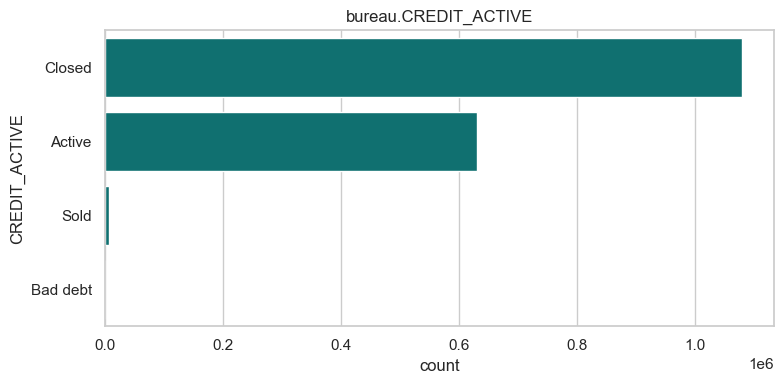

[decision] bureau.CREDIT_ACTIVE: keep as-is (none)


In [5]:
feature_report(bureau, "CREDIT_ACTIVE", "bureau")
plot_categorical(bureau["CREDIT_ACTIVE"], "bureau.CREDIT_ACTIVE")
record("bureau", "CREDIT_ACTIVE", "none", "keep as-is")

## Feature: `CREDIT_CURRENCY`


=== bureau.CREDIT_CURRENCY ===
dtype=object  missing=0 (0.00%)
n_unique=4


CREDIT_CURRENCY
currency 1    1715020
currency 2       1224
currency 3        174
currency 4         10
Name: count, dtype: int64

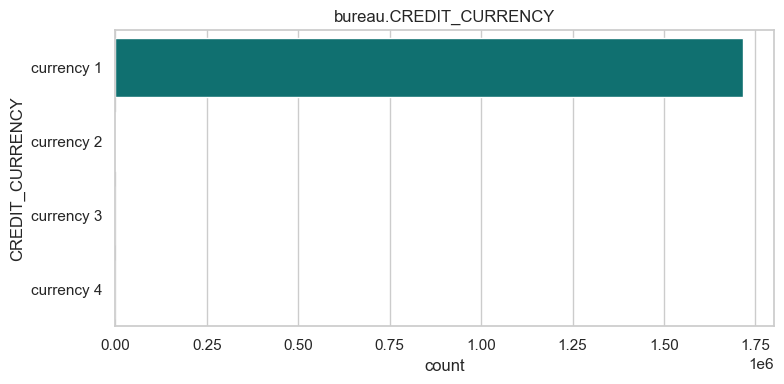

[decision] bureau.CREDIT_CURRENCY: keep but low modelling value; may drop later (almost all one currency)


In [6]:
feature_report(bureau, "CREDIT_CURRENCY", "bureau")
plot_categorical(bureau["CREDIT_CURRENCY"], "bureau.CREDIT_CURRENCY")
record(
    "bureau",
    "CREDIT_CURRENCY",
    "almost all one currency",
    "keep but low modelling value; may drop later",
)

## Feature: `DAYS_CREDIT`

Days before application the credit was opened (should be <= 0).


=== bureau.DAYS_CREDIT ===
dtype=int64  missing=0 (0.00%)
n_unique=2923


count    1.716428e+06
mean    -1.142108e+03
std      7.951649e+02
min     -2.922000e+03
25%     -1.666000e+03
50%     -9.870000e+02
75%     -4.740000e+02
max      0.000000e+00
Name: DAYS_CREDIT, dtype: float64

DAYS_CREDIT > 0: 0


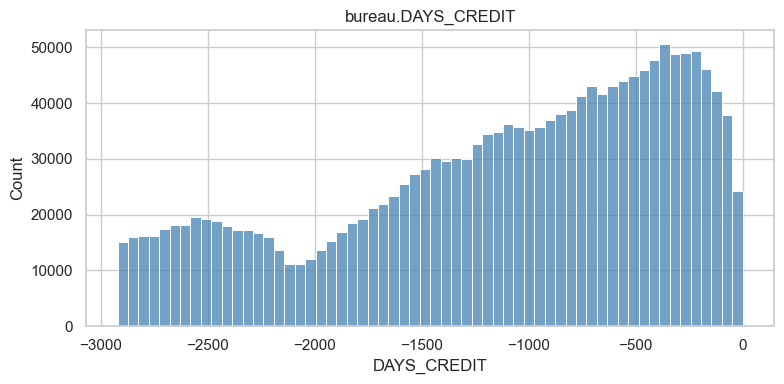

[decision] bureau.DAYS_CREDIT: keep; require <= 0 for application-time features (relative offset)


In [7]:
feature_report(bureau, "DAYS_CREDIT", "bureau")
print("DAYS_CREDIT > 0:", int((bureau["DAYS_CREDIT"] > 0).sum()))
fig, ax = plt.subplots(figsize=(8, 4))
plot_numeric(bureau["DAYS_CREDIT"], "bureau.DAYS_CREDIT", bins=60, ax=ax)
plt.tight_layout()
plt.show()
record(
    "bureau",
    "DAYS_CREDIT",
    "relative offset",
    "keep; require <= 0 for application-time features",
)

## Feature: `CREDIT_DAY_OVERDUE`


=== bureau.CREDIT_DAY_OVERDUE ===
dtype=int64  missing=0 (0.00%)
n_unique=942


count    1.716428e+06
mean     8.181666e-01
std      3.654443e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.792000e+03
Name: CREDIT_DAY_OVERDUE, dtype: float64

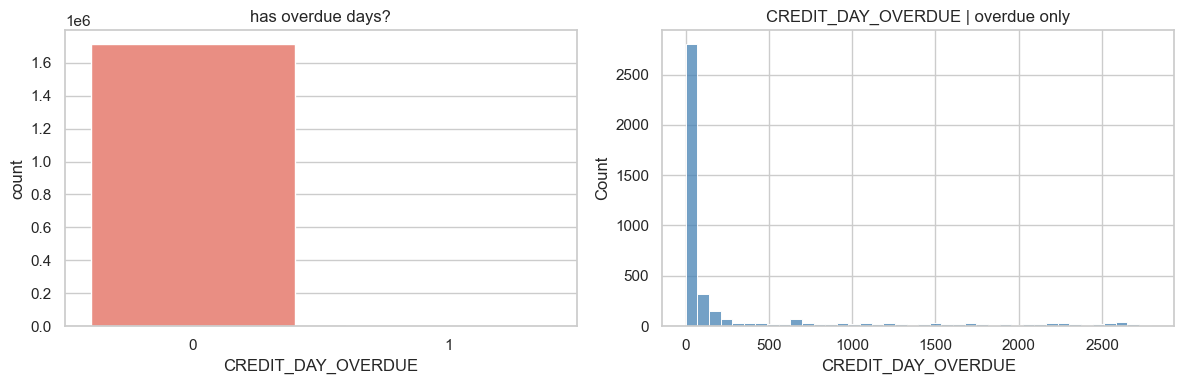

[decision] bureau.CREDIT_DAY_OVERDUE: keep as-is (sparse positive overdue)


In [8]:
feature_report(bureau, "CREDIT_DAY_OVERDUE", "bureau")
s = bureau["CREDIT_DAY_OVERDUE"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=(s > 0).astype(int), ax=axes[0], color="salmon")
axes[0].set_title("has overdue days?")
plot_numeric(s[s > 0], "CREDIT_DAY_OVERDUE | overdue only", bins=40, ax=axes[1])
plt.tight_layout()
plt.show()
record("bureau", "CREDIT_DAY_OVERDUE", "sparse positive overdue", "keep as-is")

## Feature: `DAYS_CREDIT_ENDDATE`

Can be positive (planned end after application). Not a dirty spike; document carefully for leakage.


=== bureau.DAYS_CREDIT_ENDDATE ===
dtype=float64  missing=105,553 (6.15%)
n_unique=14096


count    1.610875e+06
mean     5.105174e+02
std      4.994220e+03
min     -4.206000e+04
25%     -1.138000e+03
50%     -3.300000e+02
75%      4.740000e+02
max      3.119900e+04
Name: DAYS_CREDIT_ENDDATE, dtype: float64

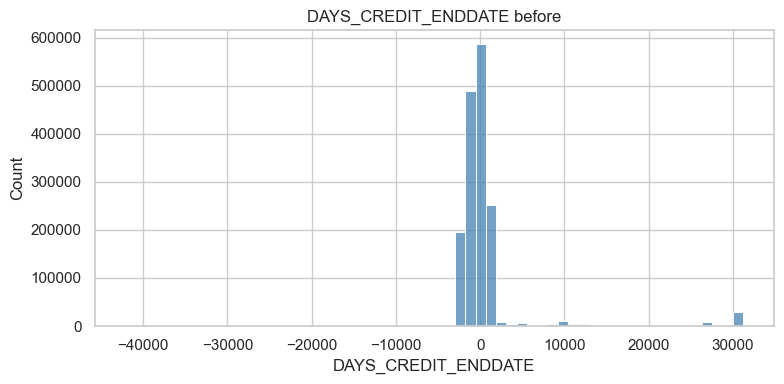

>0 (after app): 602603
<0 (before app): 1007389
[decision] bureau.DAYS_CREDIT_ENDDATE: keep NaN + missing flag; for PD features prefer closed/past info only (missing + future end dates (>0))


In [9]:
feature_report(bureau, "DAYS_CREDIT_ENDDATE", "bureau")
before = bureau["DAYS_CREDIT_ENDDATE"].copy()
fig, ax = plt.subplots(figsize=(8, 4))
plot_numeric(before, "DAYS_CREDIT_ENDDATE before", bins=60, ax=ax)
plt.tight_layout()
plt.show()

bureau["DAYS_CREDIT_ENDDATE_MISSING"] = bureau["DAYS_CREDIT_ENDDATE"].isna().astype("int8")
print(">0 (after app):", int((bureau["DAYS_CREDIT_ENDDATE"] > 0).sum()))
print("<0 (before app):", int((bureau["DAYS_CREDIT_ENDDATE"] < 0).sum()))

record(
    "bureau",
    "DAYS_CREDIT_ENDDATE",
    "missing + future end dates (>0)",
    "keep NaN + missing flag; for PD features prefer closed/past info only",
)

## Feature: `DAYS_ENDDATE_FACT`


=== bureau.DAYS_ENDDATE_FACT ===
dtype=float64  missing=633,653 (36.92%)
n_unique=2917


count    1.082775e+06
mean    -1.017437e+03
std      7.140106e+02
min     -4.202300e+04
25%     -1.489000e+03
50%     -8.970000e+02
75%     -4.250000e+02
max      0.000000e+00
Name: DAYS_ENDDATE_FACT, dtype: float64

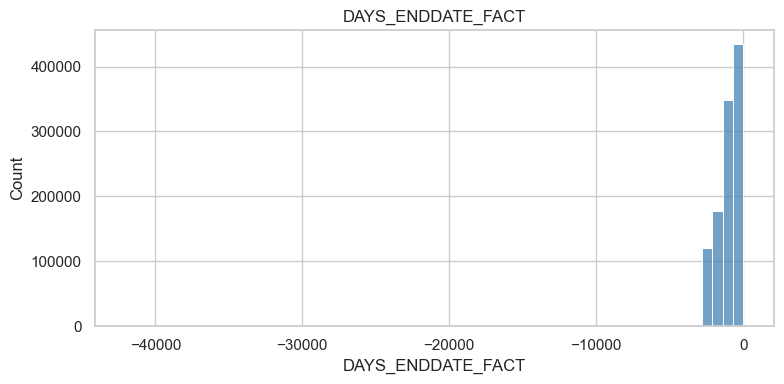

[decision] bureau.DAYS_ENDDATE_FACT: keep NaN + missing flag (missing when still active)


In [10]:
feature_report(bureau, "DAYS_ENDDATE_FACT", "bureau")
fig, ax = plt.subplots(figsize=(8, 4))
plot_numeric(bureau["DAYS_ENDDATE_FACT"], "DAYS_ENDDATE_FACT", bins=60, ax=ax)
plt.tight_layout()
plt.show()
bureau["DAYS_ENDDATE_FACT_MISSING"] = bureau["DAYS_ENDDATE_FACT"].isna().astype("int8")
record(
    "bureau",
    "DAYS_ENDDATE_FACT",
    "missing when still active",
    "keep NaN + missing flag",
)

## Feature: `AMT_CREDIT_MAX_OVERDUE`


=== bureau.AMT_CREDIT_MAX_OVERDUE ===
dtype=float64  missing=1,124,488 (65.51%)
n_unique=68251


count    5.919400e+05
mean     3.825418e+03
std      2.060316e+05
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.159872e+08
Name: AMT_CREDIT_MAX_OVERDUE, dtype: float64

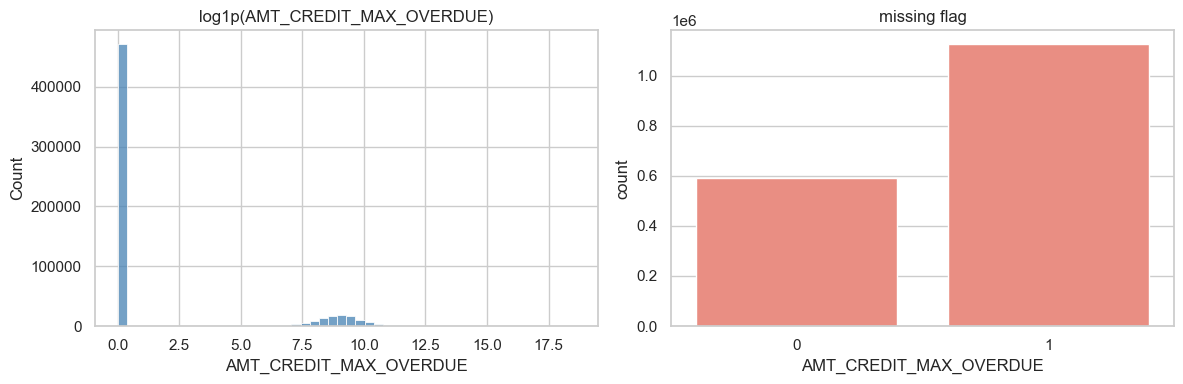

[decision] bureau.AMT_CREDIT_MAX_OVERDUE: keep NaN + missing flag (high missing)


In [11]:
feature_report(bureau, "AMT_CREDIT_MAX_OVERDUE", "bureau")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_numeric(
    np.log1p(bureau["AMT_CREDIT_MAX_OVERDUE"]),
    "log1p(AMT_CREDIT_MAX_OVERDUE)",
    ax=axes[0],
)
sns.countplot(x=bureau["AMT_CREDIT_MAX_OVERDUE"].isna().astype(int), ax=axes[1], color="salmon")
axes[1].set_title("missing flag")
plt.tight_layout()
plt.show()
bureau["AMT_CREDIT_MAX_OVERDUE_MISSING"] = bureau["AMT_CREDIT_MAX_OVERDUE"].isna().astype("int8")
record(
    "bureau",
    "AMT_CREDIT_MAX_OVERDUE",
    "high missing",
    "keep NaN + missing flag",
)

## Features: `AMT_CREDIT_SUM`, `AMT_CREDIT_SUM_DEBT`, `AMT_CREDIT_SUM_LIMIT`, `AMT_CREDIT_SUM_OVERDUE`


=== bureau.AMT_CREDIT_SUM ===
dtype=float64  missing=13 (0.00%)
n_unique=236708


count    1.716415e+06
mean     3.549946e+05
std      1.149811e+06
min      0.000000e+00
25%      5.130000e+04
50%      1.255185e+05
75%      3.150000e+05
max      5.850000e+08
Name: AMT_CREDIT_SUM, dtype: float64

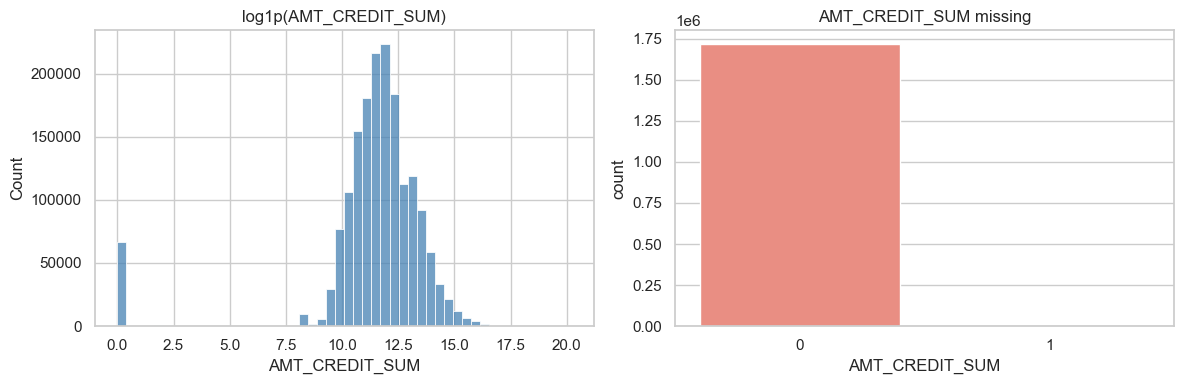

[decision] bureau.AMT_CREDIT_SUM: keep NaN + AMT_CREDIT_SUM_MISSING (missing values)

=== bureau.AMT_CREDIT_SUM_DEBT ===
dtype=float64  missing=257,669 (15.01%)
n_unique=226537


count    1.458759e+06
mean     1.370851e+05
std      6.774011e+05
min     -4.705600e+06
25%      0.000000e+00
50%      0.000000e+00
75%      4.015350e+04
max      1.701000e+08
Name: AMT_CREDIT_SUM_DEBT, dtype: float64

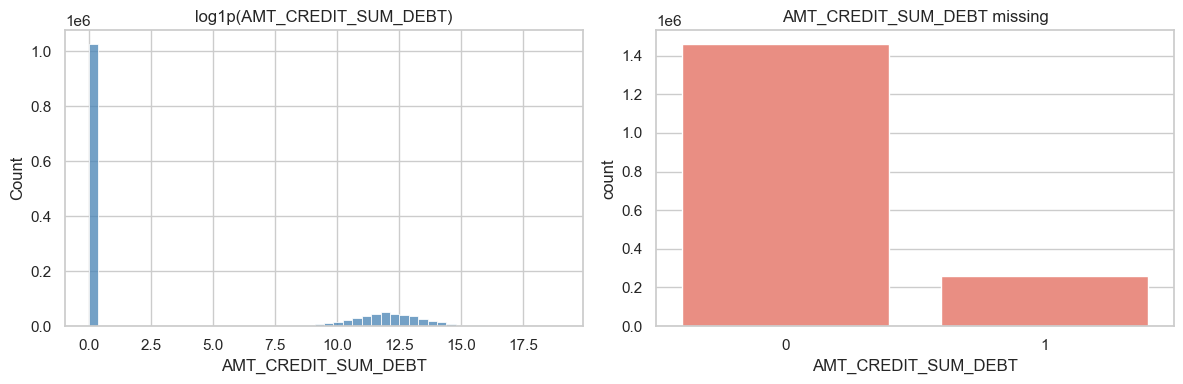

[decision] bureau.AMT_CREDIT_SUM_DEBT: keep NaN + AMT_CREDIT_SUM_DEBT_MISSING (missing values)

=== bureau.AMT_CREDIT_SUM_LIMIT ===
dtype=float64  missing=591,780 (34.48%)
n_unique=51726


count    1.124648e+06
mean     6.229515e+03
std      4.503203e+04
min     -5.864061e+05
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      4.705600e+06
Name: AMT_CREDIT_SUM_LIMIT, dtype: float64

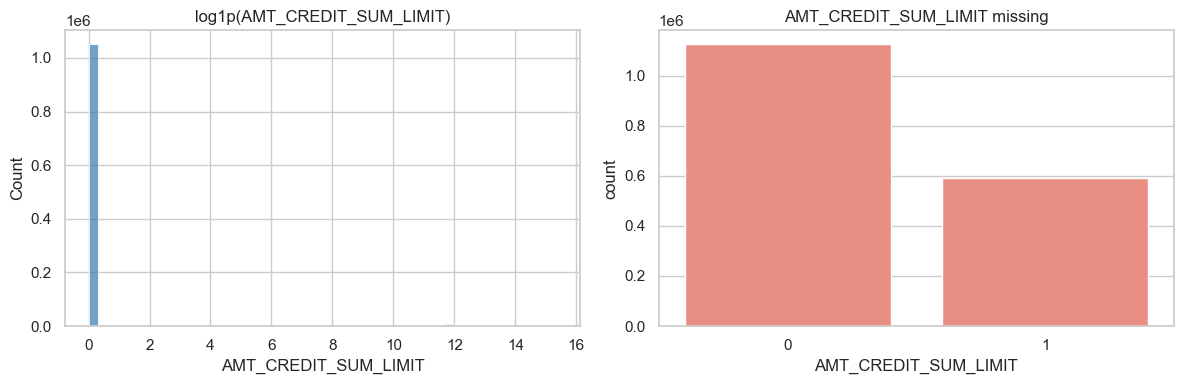

[decision] bureau.AMT_CREDIT_SUM_LIMIT: keep NaN + AMT_CREDIT_SUM_LIMIT_MISSING (missing values)

=== bureau.AMT_CREDIT_SUM_OVERDUE ===
dtype=float64  missing=0 (0.00%)
n_unique=1616


count    1.716428e+06
mean     3.791276e+01
std      5.937650e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.756681e+06
Name: AMT_CREDIT_SUM_OVERDUE, dtype: float64

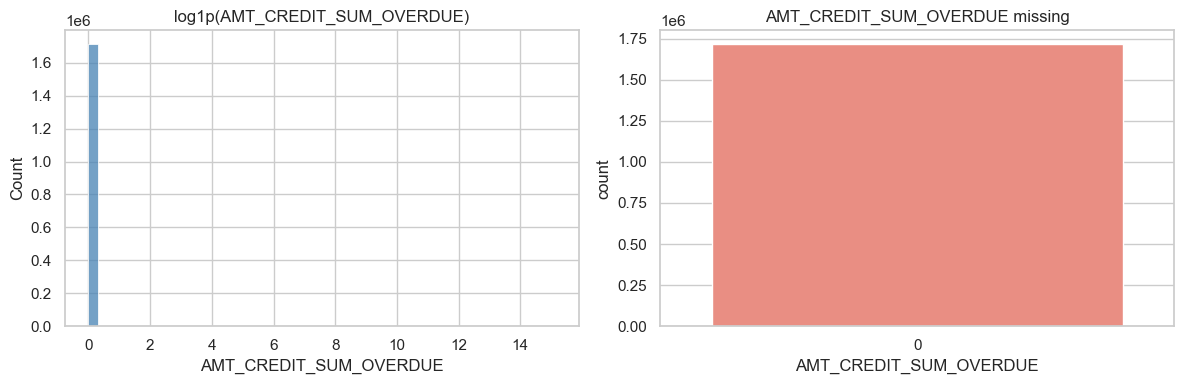

[decision] bureau.AMT_CREDIT_SUM_OVERDUE: keep as-is (none)


In [12]:
amt_cols = [
    "AMT_CREDIT_SUM",
    "AMT_CREDIT_SUM_DEBT",
    "AMT_CREDIT_SUM_LIMIT",
    "AMT_CREDIT_SUM_OVERDUE",
]
for col in amt_cols:
    feature_report(bureau, col, "bureau")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    plot_numeric(np.log1p(bureau[col].clip(lower=0)), f"log1p({col})", ax=axes[0])
    sns.countplot(x=bureau[col].isna().astype(int), ax=axes[1], color="salmon")
    axes[1].set_title(f"{col} missing")
    plt.tight_layout()
    plt.show()
    if bureau[col].isna().any():
        bureau[f"{col}_MISSING"] = bureau[col].isna().astype("int8")
        record("bureau", col, "missing values", f"keep NaN + {col}_MISSING")
    else:
        record("bureau", col, "none", "keep as-is")

## Feature: `CNT_CREDIT_PROLONG`


=== bureau.CNT_CREDIT_PROLONG ===
dtype=int64  missing=0 (0.00%)
n_unique=10


count    1.716428e+06
mean     6.410406e-03
std      9.622391e-02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      9.000000e+00
Name: CNT_CREDIT_PROLONG, dtype: float64

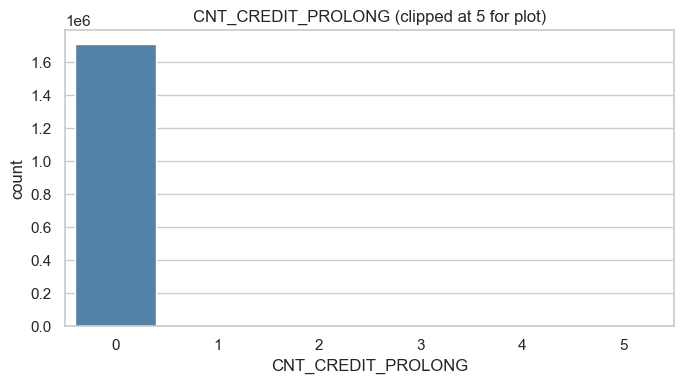

[decision] bureau.CNT_CREDIT_PROLONG: keep as-is (none)


In [13]:
feature_report(bureau, "CNT_CREDIT_PROLONG", "bureau")
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(x=bureau["CNT_CREDIT_PROLONG"].clip(upper=5), ax=ax, color="steelblue")
ax.set_title("CNT_CREDIT_PROLONG (clipped at 5 for plot)")
plt.tight_layout()
plt.show()
record("bureau", "CNT_CREDIT_PROLONG", "none", "keep as-is")

## Feature: `CREDIT_TYPE`


=== bureau.CREDIT_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=15


CREDIT_TYPE
Consumer credit                           1251615
Credit card                                402195
Car loan                                    27690
Mortgage                                    18391
Microloan                                   12413
Loan for business development                1975
Another type of loan                         1017
Unknown type of loan                          555
Loan for working capital replenishment        469
Cash loan (non-earmarked)                      56
Real estate loan                               27
Loan for the purchase of equipment             19
Name: count, dtype: int64

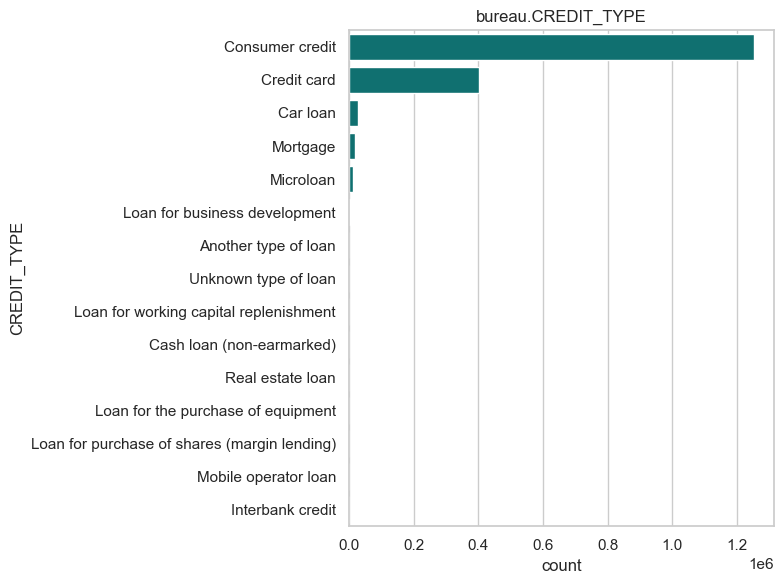

[decision] bureau.CREDIT_TYPE: keep as-is (none)


In [14]:
feature_report(bureau, "CREDIT_TYPE", "bureau")
plot_categorical(bureau["CREDIT_TYPE"], "bureau.CREDIT_TYPE", top_n=15, figsize=(8, 6))
record("bureau", "CREDIT_TYPE", "none", "keep as-is")

## Feature: `DAYS_CREDIT_UPDATE`

A few positive values exist; treat as dirty / rare.


=== bureau.DAYS_CREDIT_UPDATE ===
dtype=int64  missing=0 (0.00%)
n_unique=2982


count    1.716428e+06
mean    -5.937483e+02
std      7.207473e+02
min     -4.194700e+04
25%     -9.080000e+02
50%     -3.950000e+02
75%     -3.300000e+01
max      3.720000e+02
Name: DAYS_CREDIT_UPDATE, dtype: float64

>0 rows: 17


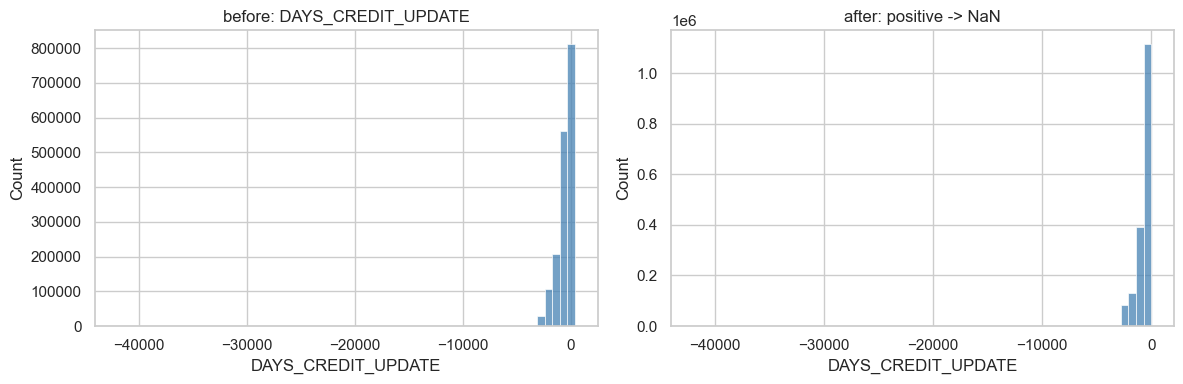

[decision] bureau.DAYS_CREDIT_UPDATE: set >0 to NaN + DAYS_CREDIT_UPDATE_POS_FLAG (17 positive values)


In [15]:
feature_report(bureau, "DAYS_CREDIT_UPDATE", "bureau")
n_pos = int((bureau["DAYS_CREDIT_UPDATE"] > 0).sum())
print(">0 rows:", n_pos)

before = bureau["DAYS_CREDIT_UPDATE"].copy()
bureau.loc[bureau["DAYS_CREDIT_UPDATE"] > 0, "DAYS_CREDIT_UPDATE"] = np.nan
bureau["DAYS_CREDIT_UPDATE_POS_FLAG"] = (before > 0).astype("int8")

before_after_numeric(
    before,
    bureau["DAYS_CREDIT_UPDATE"],
    "before: DAYS_CREDIT_UPDATE",
    "after: positive -> NaN",
    bins=60,
)
record(
    "bureau",
    "DAYS_CREDIT_UPDATE",
    f"{n_pos} positive values",
    "set >0 to NaN + DAYS_CREDIT_UPDATE_POS_FLAG",
)

## Feature: `AMT_ANNUITY` (bureau)


=== bureau.AMT_ANNUITY ===
dtype=float64  missing=1,226,791 (71.47%)
n_unique=40321


count    4.896370e+05
mean     1.571276e+04
std      3.258269e+05
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.350000e+04
max      1.184534e+08
Name: AMT_ANNUITY, dtype: float64

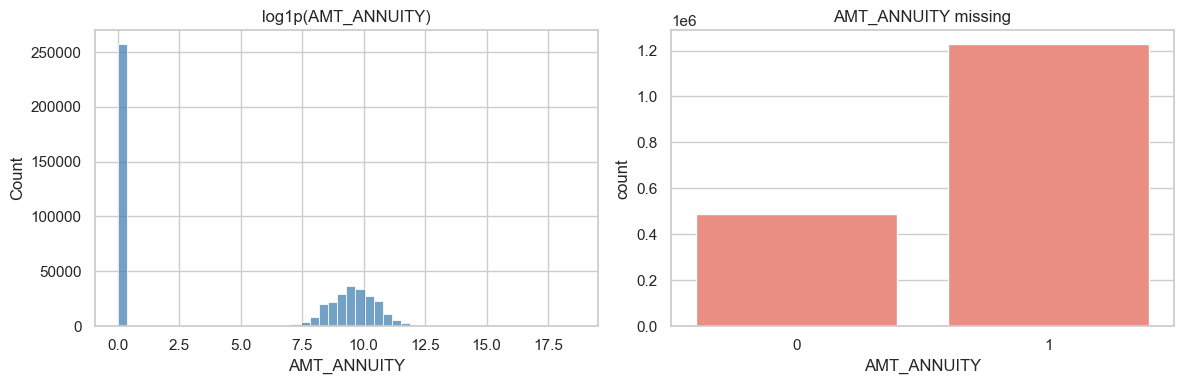

[decision] bureau.AMT_ANNUITY: keep NaN + missing flag; use cautiously in aggregates (very high missing (~70%+))


In [16]:
feature_report(bureau, "AMT_ANNUITY", "bureau")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_numeric(np.log1p(bureau["AMT_ANNUITY"]), "log1p(AMT_ANNUITY)", ax=axes[0])
sns.countplot(x=bureau["AMT_ANNUITY"].isna().astype(int), ax=axes[1], color="salmon")
axes[1].set_title("AMT_ANNUITY missing")
plt.tight_layout()
plt.show()
bureau["AMT_ANNUITY_MISSING"] = bureau["AMT_ANNUITY"].isna().astype("int8")
record(
    "bureau",
    "AMT_ANNUITY",
    "very high missing (~70%+)",
    "keep NaN + missing flag; use cautiously in aggregates",
)

In [17]:
bureau_out = PROCESSED_DATA_DIR / "bureau_clean.parquet"
bureau.to_parquet(bureau_out, index=False)
print("wrote", bureau_out, "shape", bureau.shape)
del bureau
gc.collect()

wrote C:\Users\user\Desktop\Credit-Scoring Project\data\processed\bureau_clean.parquet shape (1716428, 25)


66639

---
# B. `bureau_balance.csv`

Monthly bureau status. Large file -- sample for plots, chunked counts for full-data stats.

file_mb: 358.2


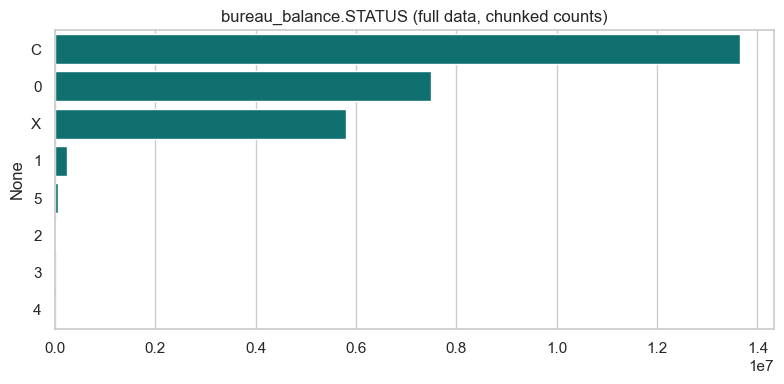

C    13646993
0     7499507
X     5810482
1      242347
5       62406
2       23419
3        8924
4        5847
dtype: int64


=== bureau_balance(sample).MONTHS_BALANCE ===
dtype=int64  missing=0 (0.00%)
n_unique=97


count    80000.000000
mean       -29.669200
std         23.265612
min        -96.000000
25%        -44.000000
50%        -24.000000
75%        -11.000000
max          0.000000
Name: MONTHS_BALANCE, dtype: float64

MONTHS_BALANCE > 0 in sample: 0


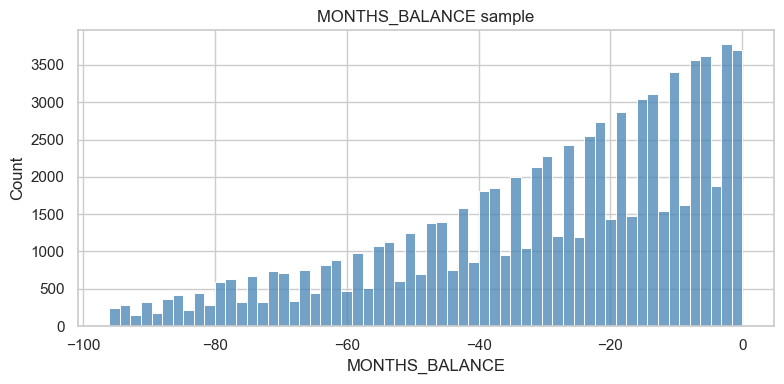

[decision] bureau_balance.STATUS: keep; C=closed, X=unknown, 0-5 DPD buckets (none)
[decision] bureau_balance.MONTHS_BALANCE: keep; use only MONTHS_BALANCE <= 0 at feature time (relative month offset)
[decision] bureau_balance.table: no full rewrite; cleaning rules applied in DuckDB SQL later (very large)


8286

In [18]:
bb_path = RAW_DATA_DIR / "bureau_balance.csv"
print("file_mb:", round(bb_path.stat().st_size / 1024**2, 1))

status_counts = chunked_value_counts(bb_path, "STATUS", top_n=20)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=status_counts.values, y=status_counts.index.astype(str), ax=ax, color="teal")
ax.set_title("bureau_balance.STATUS (full data, chunked counts)")
plt.tight_layout()
plt.show()
display(status_counts)

bb_sample = sample_csv(bb_path, n=SAMPLE_N)
feature_report(bb_sample, "MONTHS_BALANCE", "bureau_balance(sample)")
print("MONTHS_BALANCE > 0 in sample:", int((bb_sample["MONTHS_BALANCE"] > 0).sum()))
fig, ax = plt.subplots(figsize=(8, 4))
plot_numeric(bb_sample["MONTHS_BALANCE"], "MONTHS_BALANCE sample", bins=60, ax=ax)
plt.tight_layout()
plt.show()

record("bureau_balance", "STATUS", "none", "keep; C=closed, X=unknown, 0-5 DPD buckets")
record(
    "bureau_balance",
    "MONTHS_BALANCE",
    "relative month offset",
    "keep; use only MONTHS_BALANCE <= 0 at feature time",
)
record(
    "bureau_balance",
    "table",
    "very large",
    "no full rewrite; cleaning rules applied in DuckDB SQL later",
)

del bb_sample
gc.collect()

---
# C. `previous_application.csv`

Prior Home Credit applications. Day fields often use sentinel `365243`.

shape: (1670214, 37)


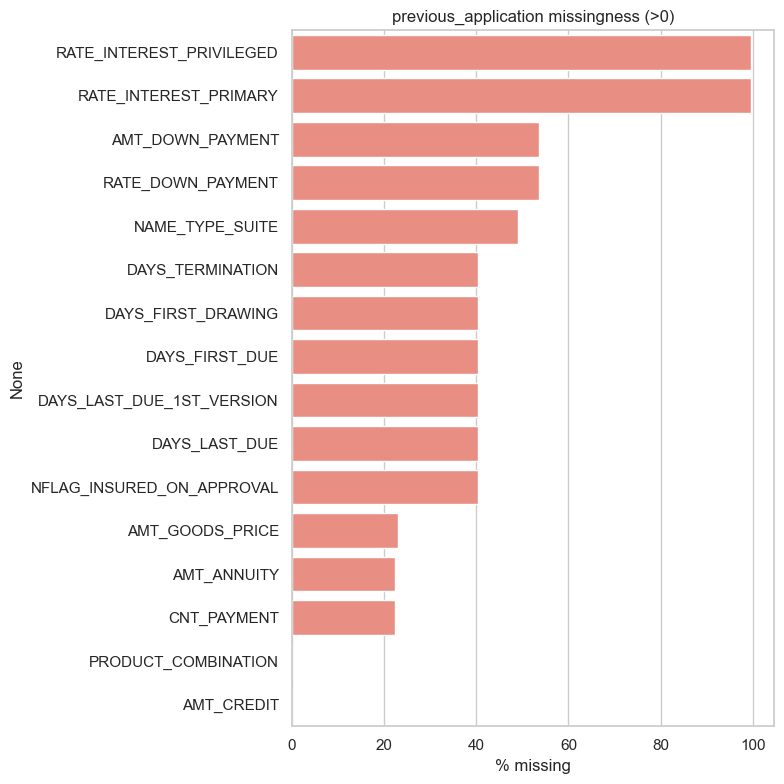

In [19]:
prev_path = RAW_DATA_DIR / "previous_application.csv"
prev = pd.read_csv(prev_path, low_memory=False)
print("shape:", prev.shape)

miss = (prev.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(x=miss.values, y=miss.index, ax=ax, color="salmon")
ax.set_title("previous_application missingness (>0)")
ax.set_xlabel("% missing")
plt.tight_layout()
plt.show()

## Feature: `NAME_CONTRACT_STATUS`


=== previous_application.NAME_CONTRACT_STATUS ===
dtype=object  missing=0 (0.00%)
n_unique=4


NAME_CONTRACT_STATUS
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436
Name: count, dtype: int64

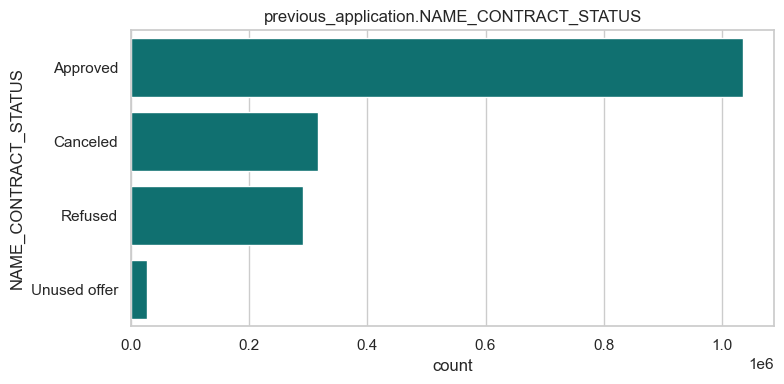

[decision] previous_application.NAME_CONTRACT_STATUS: keep; core for approval/refusal rates (none)


In [20]:
feature_report(prev, "NAME_CONTRACT_STATUS", "previous_application")
plot_categorical(prev["NAME_CONTRACT_STATUS"], "previous_application.NAME_CONTRACT_STATUS")
record("previous_application", "NAME_CONTRACT_STATUS", "none", "keep; core for approval/refusal rates")

## Feature: `DAYS_DECISION`


=== previous_application.DAYS_DECISION ===
dtype=int64  missing=0 (0.00%)
n_unique=2922


count    1.670214e+06
mean    -8.806797e+02
std      7.790997e+02
min     -2.922000e+03
25%     -1.300000e+03
50%     -5.810000e+02
75%     -2.800000e+02
max     -1.000000e+00
Name: DAYS_DECISION, dtype: float64

>0: 0
sentinel: 0


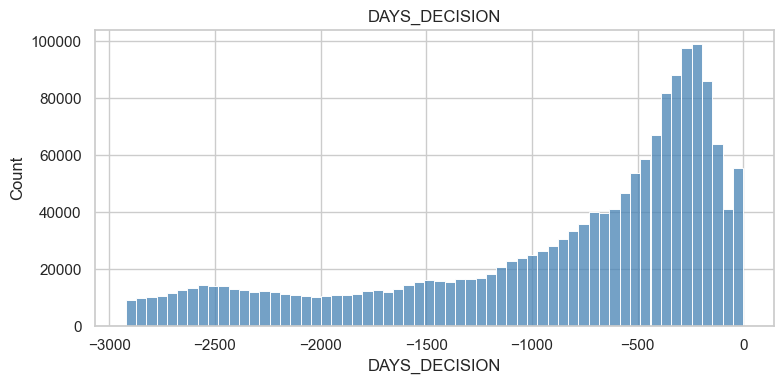

[decision] previous_application.DAYS_DECISION: keep; filter DAYS_DECISION <= 0 for application-time features (relative offset)


In [21]:
feature_report(prev, "DAYS_DECISION", "previous_application")
print(">0:", int((prev["DAYS_DECISION"] > 0).sum()))
print("sentinel:", int((prev["DAYS_DECISION"] == DAY_SENTINEL).sum()))
fig, ax = plt.subplots(figsize=(8, 4))
plot_numeric(prev["DAYS_DECISION"], "DAYS_DECISION", bins=60, ax=ax)
plt.tight_layout()
plt.show()
record(
    "previous_application",
    "DAYS_DECISION",
    "relative offset",
    "keep; filter DAYS_DECISION <= 0 for application-time features",
)

## Features: day sentinels `DAYS_FIRST_DRAWING`, `DAYS_FIRST_DUE`, `DAYS_LAST_DUE*`, `DAYS_TERMINATION`


=== previous_application.DAYS_FIRST_DRAWING ===
dtype=float64  missing=673,065 (40.30%)
n_unique=2838


count    997149.000000
mean     342209.855039
std       88916.115833
min       -2922.000000
25%      365243.000000
50%      365243.000000
75%      365243.000000
max      365243.000000
Name: DAYS_FIRST_DRAWING, dtype: float64

sentinel 365243: 934444 (55.95%)


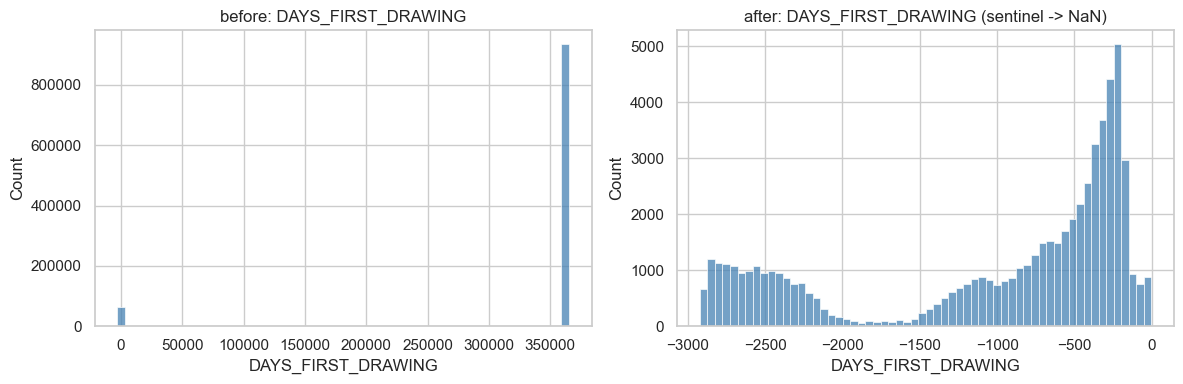

[decision] previous_application.DAYS_FIRST_DRAWING: set sentinel to NaN + DAYS_FIRST_DRAWING_ANOMALY_FLAG (sentinel 365243)

=== previous_application.DAYS_FIRST_DUE ===
dtype=float64  missing=673,065 (40.30%)
n_unique=2892


count    997149.000000
mean      13826.269337
std       72444.869708
min       -2892.000000
25%       -1628.000000
50%        -831.000000
75%        -411.000000
max      365243.000000
Name: DAYS_FIRST_DUE, dtype: float64

sentinel 365243: 40645 (2.43%)


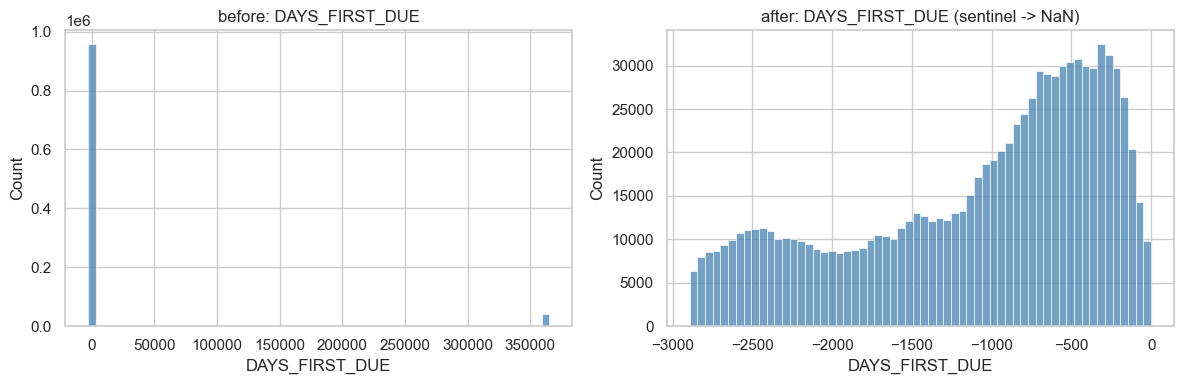

[decision] previous_application.DAYS_FIRST_DUE: set sentinel to NaN + DAYS_FIRST_DUE_ANOMALY_FLAG (sentinel 365243)

=== previous_application.DAYS_LAST_DUE_1ST_VERSION ===
dtype=float64  missing=673,065 (40.30%)
n_unique=4605


count    997149.000000
mean      33767.774054
std      106857.034789
min       -2801.000000
25%       -1242.000000
50%        -361.000000
75%         129.000000
max      365243.000000
Name: DAYS_LAST_DUE_1ST_VERSION, dtype: float64

sentinel 365243: 93864 (5.62%)


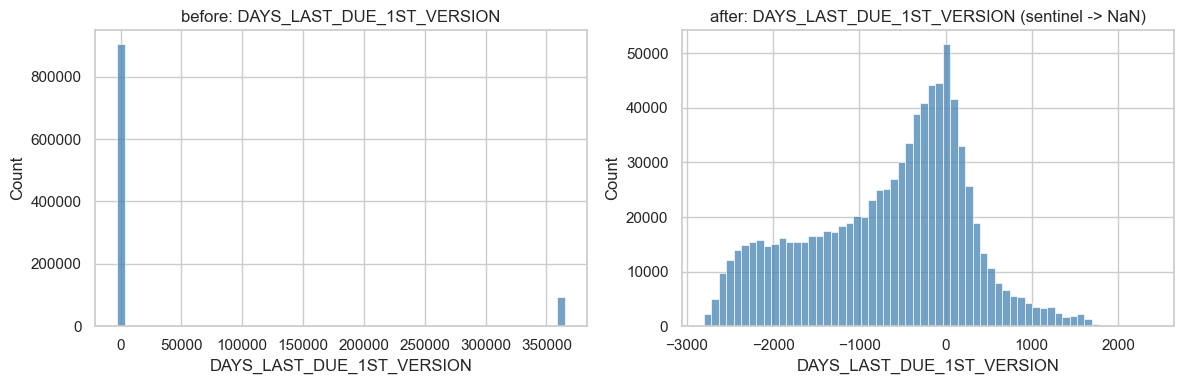

[decision] previous_application.DAYS_LAST_DUE_1ST_VERSION: set sentinel to NaN + DAYS_LAST_DUE_1ST_VERSION_ANOMALY_FLAG (sentinel 365243)

=== previous_application.DAYS_LAST_DUE ===
dtype=float64  missing=673,065 (40.30%)
n_unique=2873


count    997149.000000
mean      76582.403064
std      149647.415123
min       -2889.000000
25%       -1314.000000
50%        -537.000000
75%         -74.000000
max      365243.000000
Name: DAYS_LAST_DUE, dtype: float64

sentinel 365243: 211221 (12.65%)


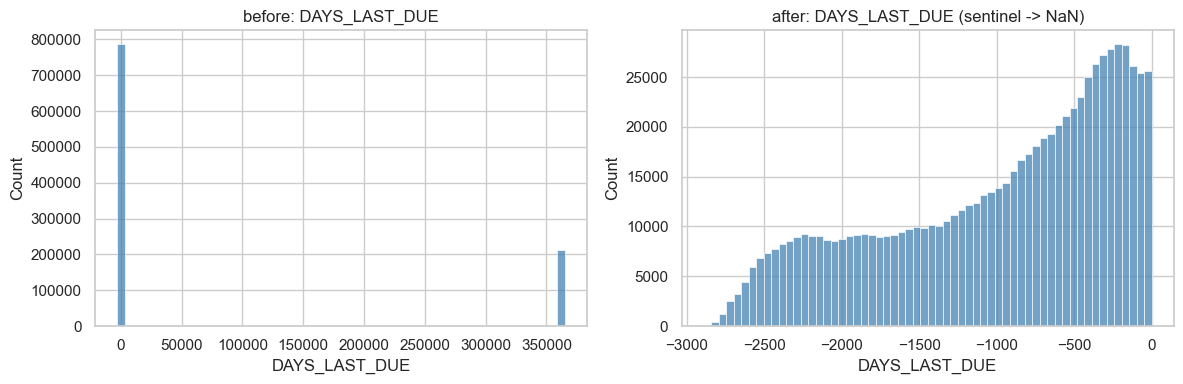

[decision] previous_application.DAYS_LAST_DUE: set sentinel to NaN + DAYS_LAST_DUE_ANOMALY_FLAG (sentinel 365243)

=== previous_application.DAYS_TERMINATION ===
dtype=float64  missing=673,065 (40.30%)
n_unique=2830


count    997149.000000
mean      81992.343838
std      153303.516729
min       -2874.000000
25%       -1270.000000
50%        -499.000000
75%         -44.000000
max      365243.000000
Name: DAYS_TERMINATION, dtype: float64

sentinel 365243: 225913 (13.53%)


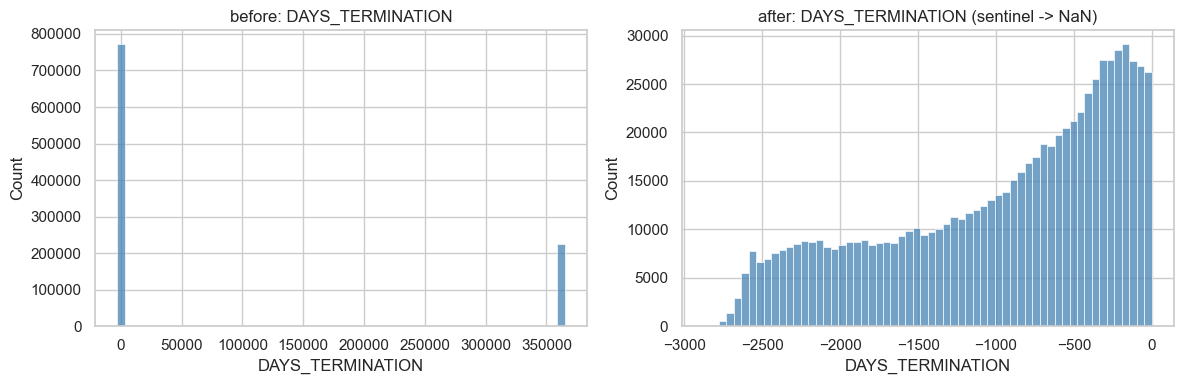

[decision] previous_application.DAYS_TERMINATION: set sentinel to NaN + DAYS_TERMINATION_ANOMALY_FLAG (sentinel 365243)


In [22]:
day_sentinel_cols = [
    "DAYS_FIRST_DRAWING",
    "DAYS_FIRST_DUE",
    "DAYS_LAST_DUE_1ST_VERSION",
    "DAYS_LAST_DUE",
    "DAYS_TERMINATION",
]

for col in day_sentinel_cols:
    feature_report(prev, col, "previous_application")
    before = prev[col].copy()
    n_sent = int((before == DAY_SENTINEL).sum())
    print(f"sentinel {DAY_SENTINEL}: {n_sent} ({100*n_sent/len(prev):.2f}%)")

    cleaned, flag = replace_day_sentinel(before)
    prev[col] = cleaned
    prev[f"{col}_ANOMALY_FLAG"] = flag

    before_after_numeric(
        before,
        prev[col],
        f"before: {col}",
        f"after: {col} (sentinel -> NaN)",
        bins=60,
    )
    record(
        "previous_application",
        col,
        f"sentinel {DAY_SENTINEL}",
        f"set sentinel to NaN + {col}_ANOMALY_FLAG",
        f"n={n_sent}",
    )

## Features: amounts `AMT_APPLICATION`, `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_DOWN_PAYMENT`, `AMT_GOODS_PRICE`


=== previous_application.AMT_APPLICATION ===
dtype=float64  missing=0 (0.00%)
n_unique=93885


count    1.670214e+06
mean     1.752339e+05
std      2.927798e+05
min      0.000000e+00
25%      1.872000e+04
50%      7.104600e+04
75%      1.803600e+05
max      6.905160e+06
Name: AMT_APPLICATION, dtype: float64

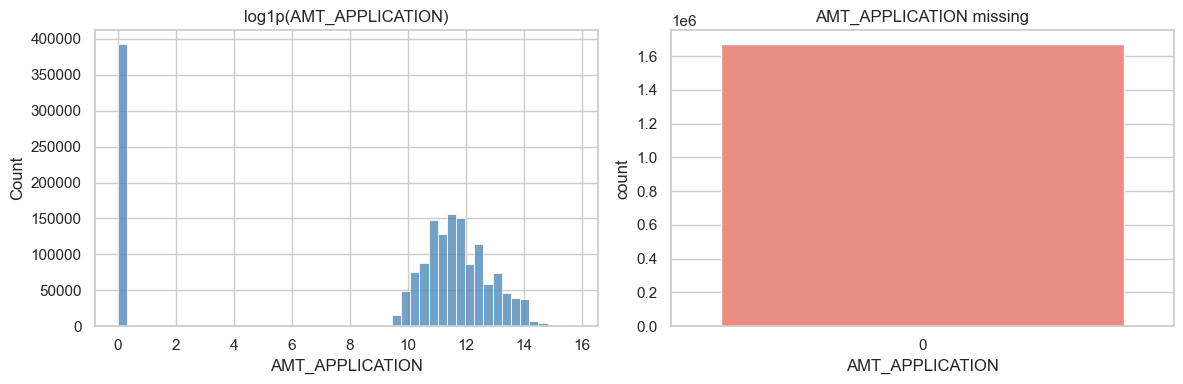

[decision] previous_application.AMT_APPLICATION: keep as-is (none)

=== previous_application.AMT_CREDIT ===
dtype=float64  missing=1 (0.00%)
n_unique=86803


count    1.670213e+06
mean     1.961140e+05
std      3.185746e+05
min      0.000000e+00
25%      2.416050e+04
50%      8.054100e+04
75%      2.164185e+05
max      6.905160e+06
Name: AMT_CREDIT, dtype: float64

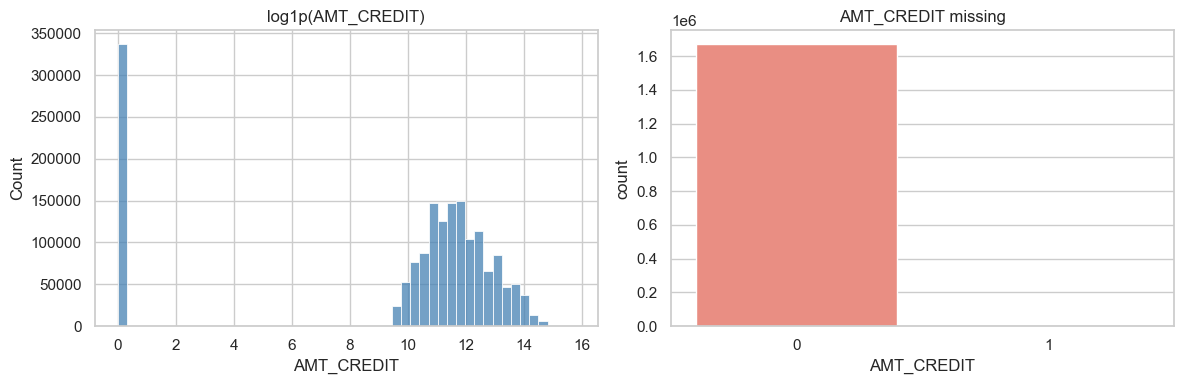

[decision] previous_application.AMT_CREDIT: keep NaN + AMT_CREDIT_MISSING (missing)

=== previous_application.AMT_ANNUITY ===
dtype=float64  missing=372,235 (22.29%)
n_unique=357959


count    1.297979e+06
mean     1.595512e+04
std      1.478214e+04
min      0.000000e+00
25%      6.321780e+03
50%      1.125000e+04
75%      2.065842e+04
max      4.180581e+05
Name: AMT_ANNUITY, dtype: float64

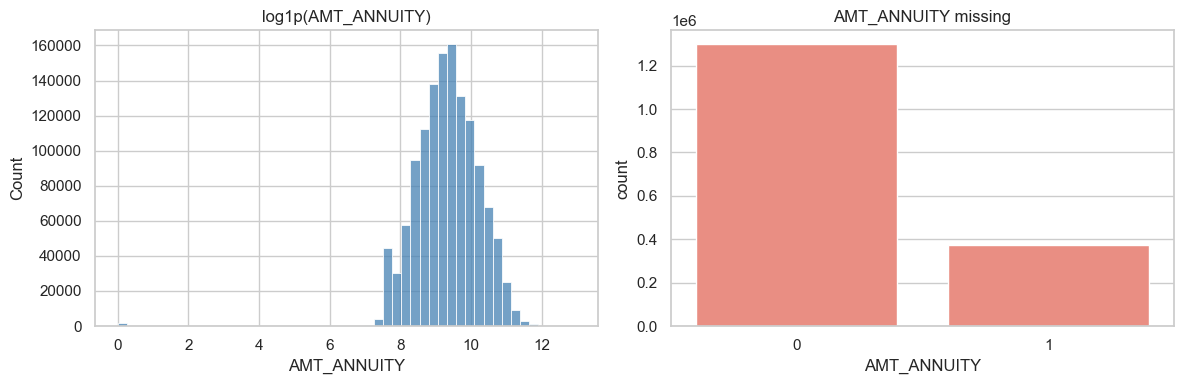

[decision] previous_application.AMT_ANNUITY: keep NaN + AMT_ANNUITY_MISSING (missing)

=== previous_application.AMT_DOWN_PAYMENT ===
dtype=float64  missing=895,844 (53.64%)
n_unique=29278


count    7.743700e+05
mean     6.697402e+03
std      2.092150e+04
min     -9.000000e-01
25%      0.000000e+00
50%      1.638000e+03
75%      7.740000e+03
max      3.060045e+06
Name: AMT_DOWN_PAYMENT, dtype: float64

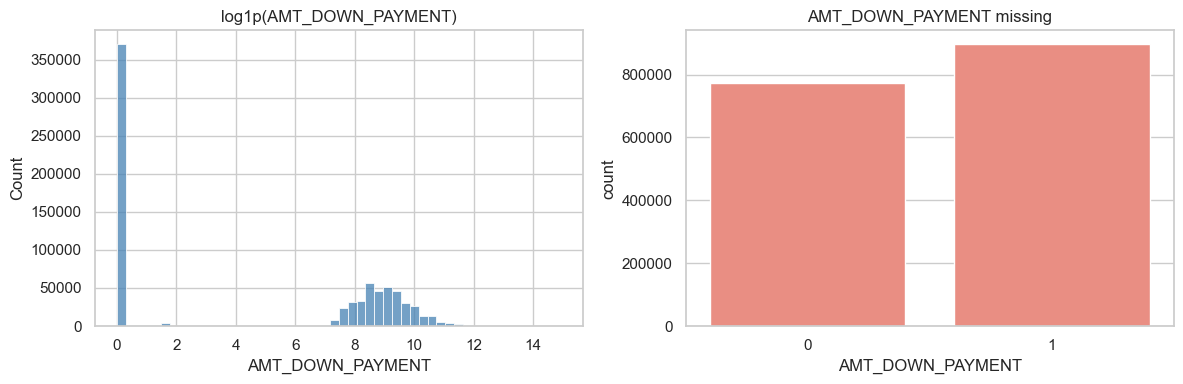

[decision] previous_application.AMT_DOWN_PAYMENT: keep NaN + AMT_DOWN_PAYMENT_MISSING (missing)

=== previous_application.AMT_GOODS_PRICE ===
dtype=float64  missing=385,515 (23.08%)
n_unique=93885


count    1.284699e+06
mean     2.278473e+05
std      3.153966e+05
min      0.000000e+00
25%      5.084100e+04
50%      1.123200e+05
75%      2.340000e+05
max      6.905160e+06
Name: AMT_GOODS_PRICE, dtype: float64

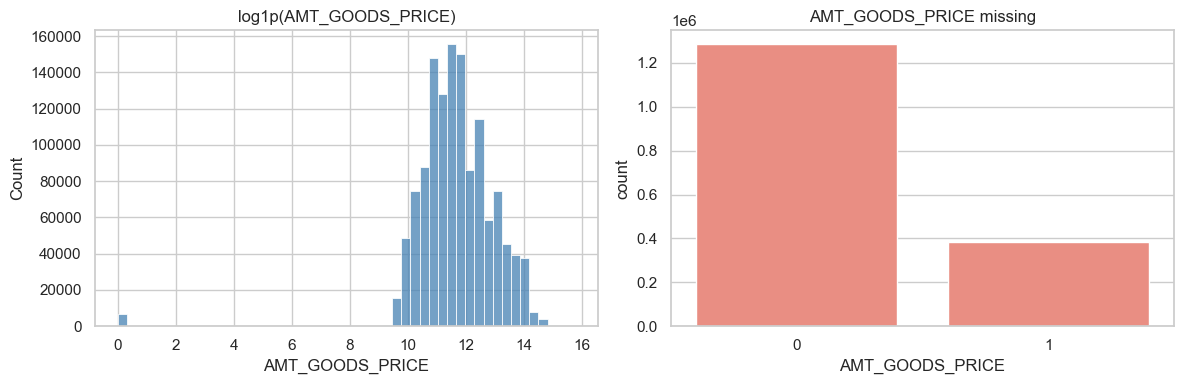

[decision] previous_application.AMT_GOODS_PRICE: keep NaN + AMT_GOODS_PRICE_MISSING (missing)


In [23]:
prev_amt_cols = [
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_DOWN_PAYMENT",
    "AMT_GOODS_PRICE",
]
for col in prev_amt_cols:
    feature_report(prev, col, "previous_application")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    plot_numeric(np.log1p(prev[col].clip(lower=0)), f"log1p({col})", ax=axes[0])
    sns.countplot(x=prev[col].isna().astype(int), ax=axes[1], color="salmon")
    axes[1].set_title(f"{col} missing")
    plt.tight_layout()
    plt.show()
    if prev[col].isna().any():
        prev[f"{col}_MISSING"] = prev[col].isna().astype("int8")
        record("previous_application", col, "missing", f"keep NaN + {col}_MISSING")
    else:
        record("previous_application", col, "none", "keep as-is")

## Features: categoricals with XNA / XAP placeholders


=== previous_application.NAME_CONTRACT_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=4


NAME_CONTRACT_TYPE
Cash loans         747553
Consumer loans     729151
Revolving loans    193164
XNA                   346
Name: count, dtype: int64

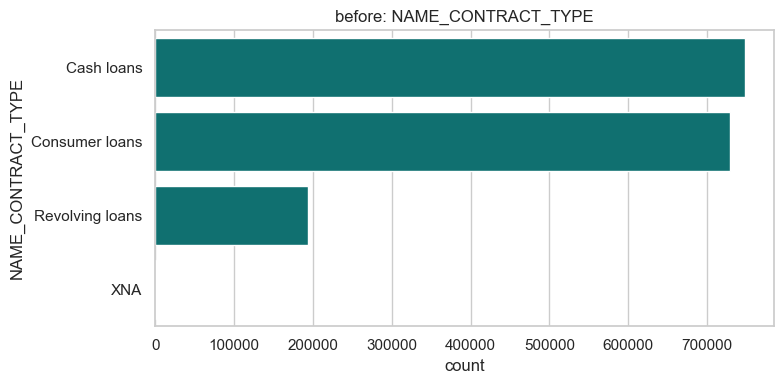

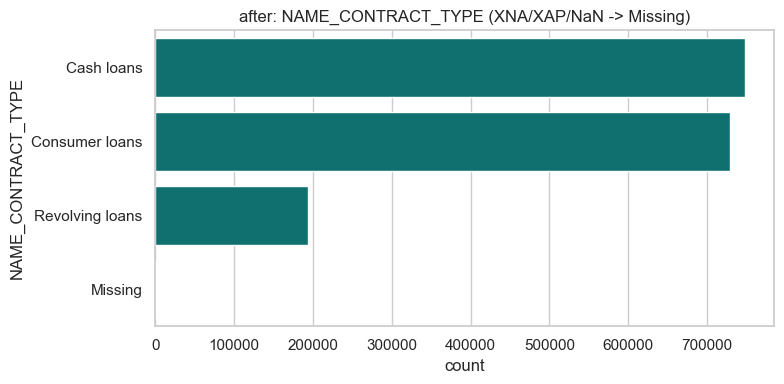

[decision] previous_application.NAME_CONTRACT_TYPE: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=346 n_miss=0)

=== previous_application.NAME_CASH_LOAN_PURPOSE ===
dtype=object  missing=0 (0.00%)
n_unique=25


NAME_CASH_LOAN_PURPOSE
XAP                             922661
XNA                             677918
Repairs                          23765
Other                            15608
Urgent needs                      8412
Buying a used car                 2888
Building a house or an annex      2693
Everyday expenses                 2416
Medicine                          2174
Payments on other loans           1931
Education                         1573
Journey                           1239
Name: count, dtype: int64

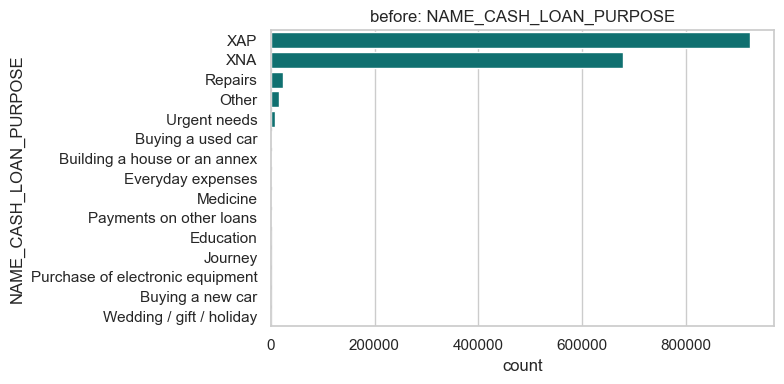

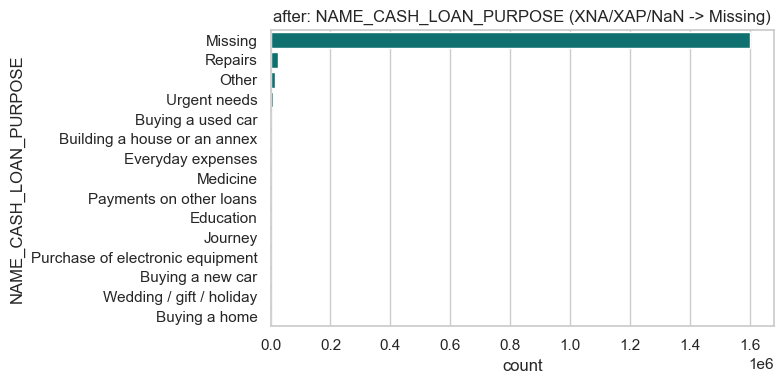

[decision] previous_application.NAME_CASH_LOAN_PURPOSE: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=1600579 n_miss=0)

=== previous_application.CODE_REJECT_REASON ===
dtype=object  missing=0 (0.00%)
n_unique=9


CODE_REJECT_REASON
XAP       1353093
HC         175231
LIMIT       55680
SCO         37467
CLIENT      26436
SCOFR       12811
XNA          5244
VERIF        3535
SYSTEM        717
Name: count, dtype: int64

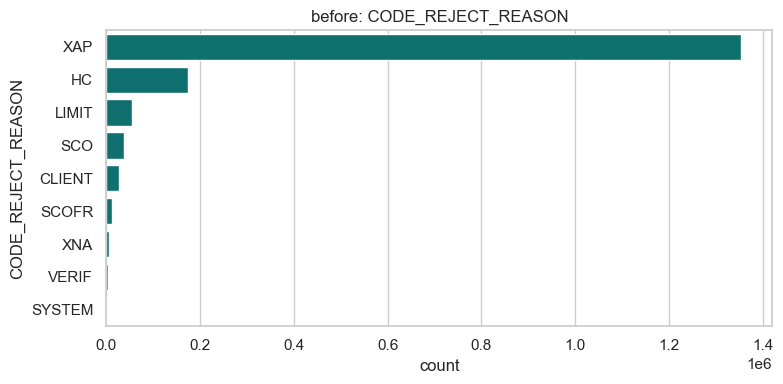

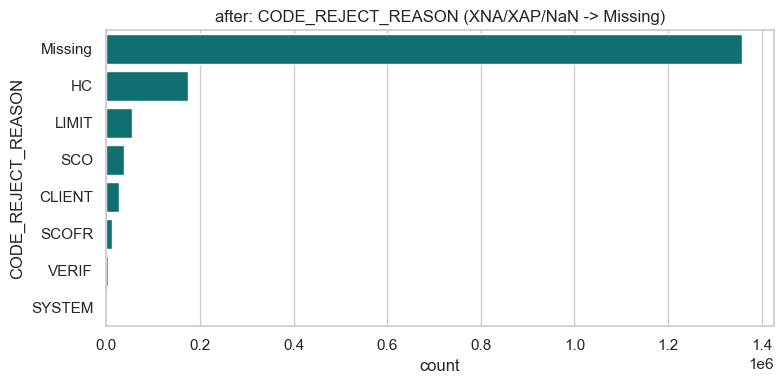

[decision] previous_application.CODE_REJECT_REASON: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=1358337 n_miss=0)

=== previous_application.NAME_CLIENT_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=4


NAME_CLIENT_TYPE
Repeater     1231261
New           301363
Refreshed     135649
XNA             1941
Name: count, dtype: int64

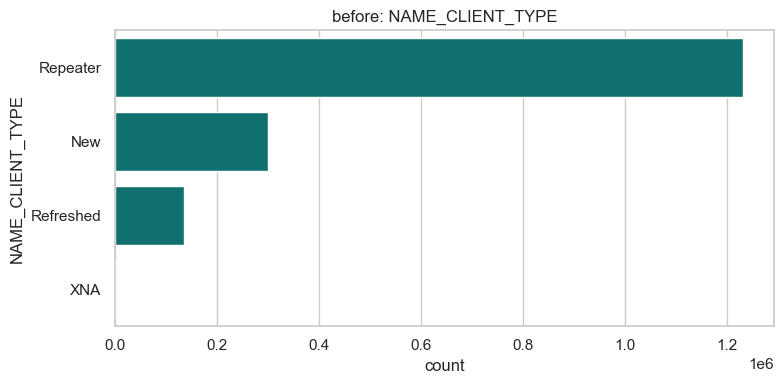

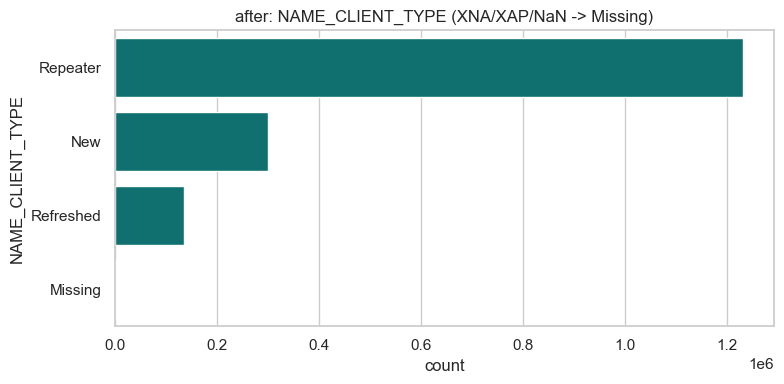

[decision] previous_application.NAME_CLIENT_TYPE: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=1941 n_miss=0)

=== previous_application.NAME_GOODS_CATEGORY ===
dtype=object  missing=0 (0.00%)
n_unique=28


NAME_GOODS_CATEGORY
XNA                         950809
Mobile                      224708
Consumer Electronics        121576
Computers                   105769
Audio/Video                  99441
Furniture                    53656
Photo / Cinema Equipment     25021
Construction Materials       24995
Clothing and Accessories     23554
Auto Accessories              7381
Jewelry                       6290
Homewares                     5023
Name: count, dtype: int64

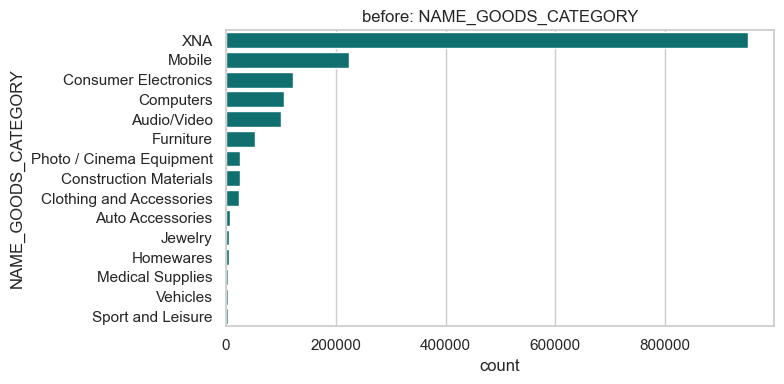

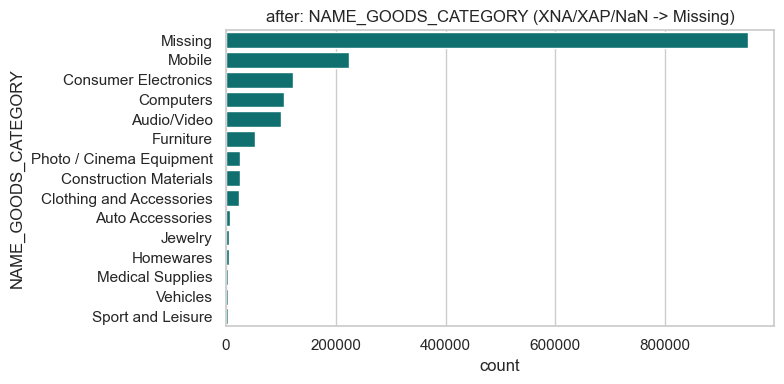

[decision] previous_application.NAME_GOODS_CATEGORY: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=950809 n_miss=0)

=== previous_application.NAME_PORTFOLIO ===
dtype=object  missing=0 (0.00%)
n_unique=5


NAME_PORTFOLIO
POS      691011
Cash     461563
XNA      372230
Cards    144985
Cars        425
Name: count, dtype: int64

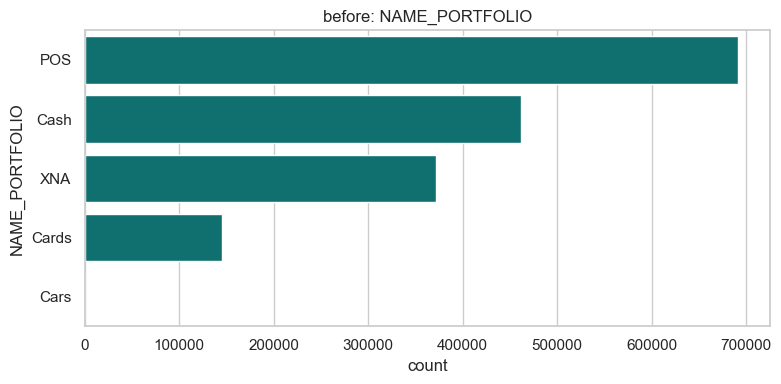

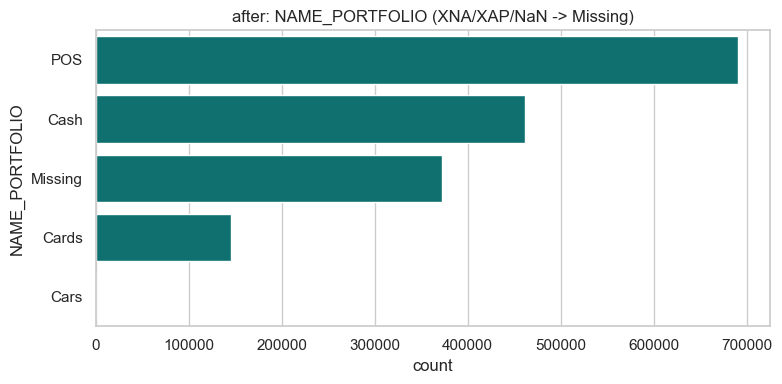

[decision] previous_application.NAME_PORTFOLIO: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=372230 n_miss=0)

=== previous_application.NAME_PRODUCT_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=3


NAME_PRODUCT_TYPE
XNA        1063666
x-sell      456287
walk-in     150261
Name: count, dtype: int64

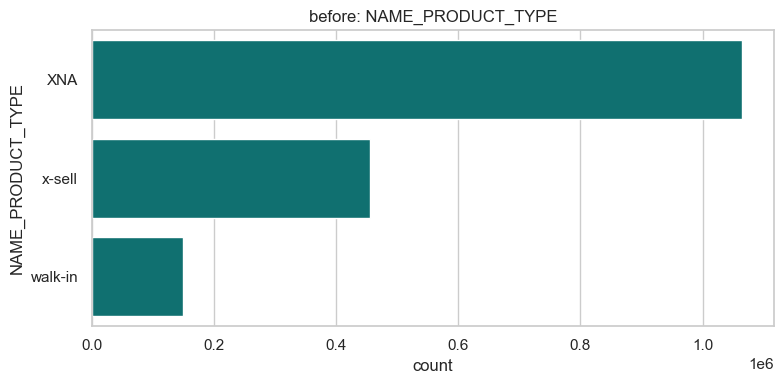

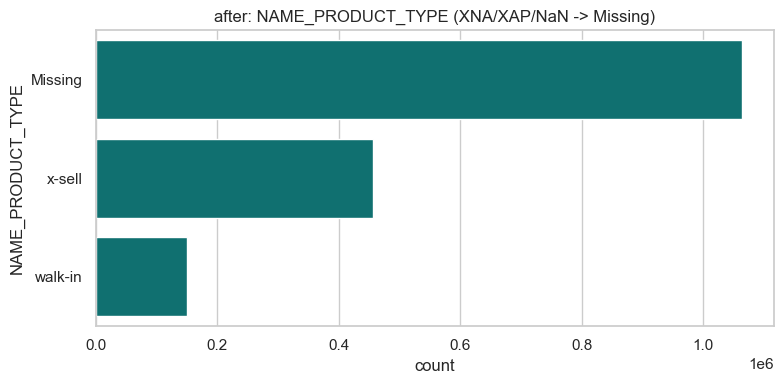

[decision] previous_application.NAME_PRODUCT_TYPE: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=1063666 n_miss=0)

=== previous_application.CHANNEL_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=8


CHANNEL_TYPE
Credit and cash offices       719968
Country-wide                  494690
Stone                         212083
Regional / Local              108528
Contact center                 71297
AP+ (Cash loan)                57046
Channel of corporate sales      6150
Car dealer                       452
Name: count, dtype: int64

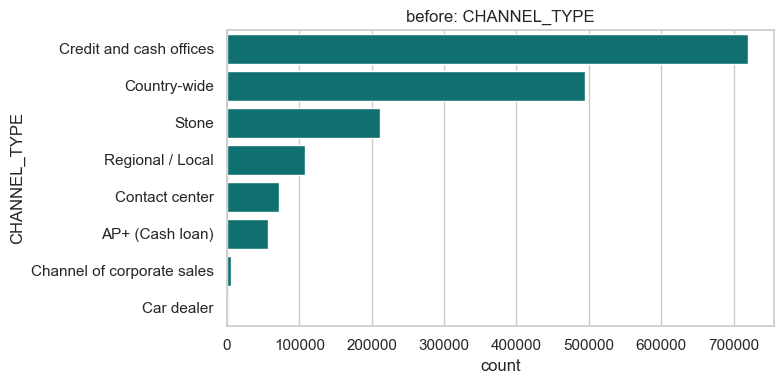

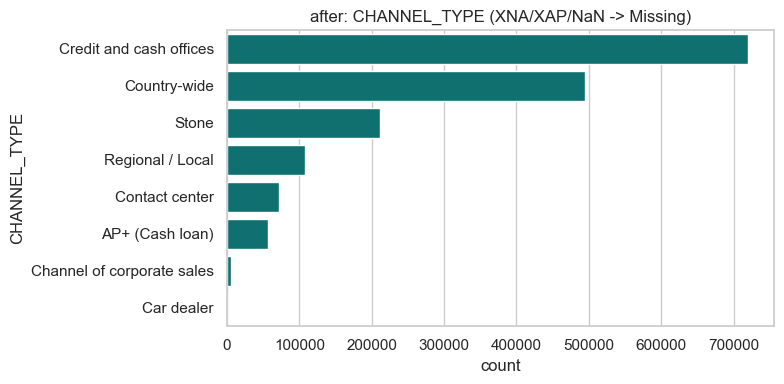

[decision] previous_application.CHANNEL_TYPE: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=0 n_miss=0)

=== previous_application.NAME_SELLER_INDUSTRY ===
dtype=object  missing=0 (0.00%)
n_unique=11


NAME_SELLER_INDUSTRY
XNA                     855720
Consumer electronics    398265
Connectivity            276029
Furniture                57849
Construction             29781
Clothing                 23949
Industry                 19194
Auto technology           4990
Jewelry                   2709
MLM partners              1215
Tourism                    513
Name: count, dtype: int64

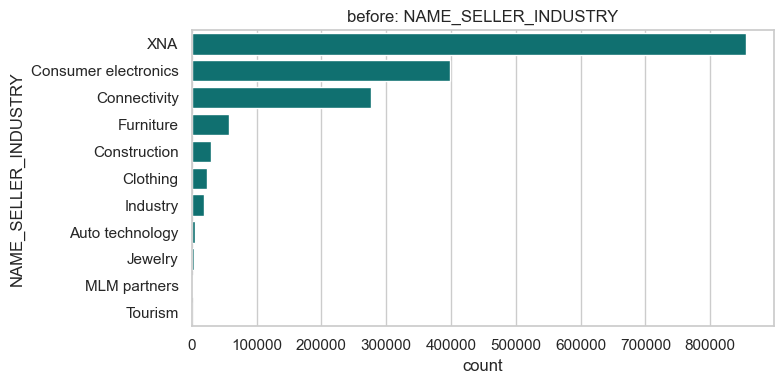

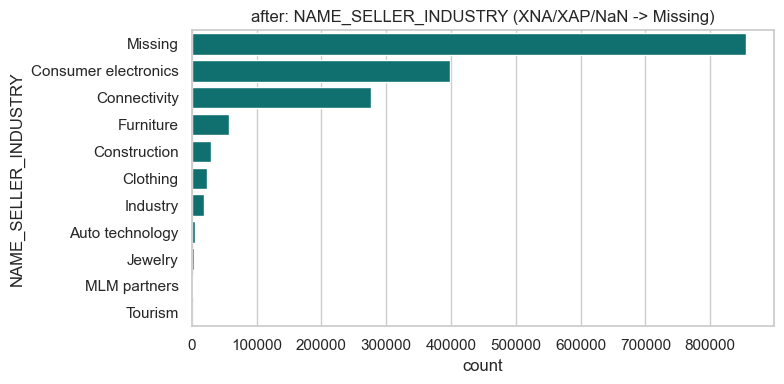

[decision] previous_application.NAME_SELLER_INDUSTRY: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=855720 n_miss=0)

=== previous_application.NAME_YIELD_GROUP ===
dtype=object  missing=0 (0.00%)
n_unique=5


NAME_YIELD_GROUP
XNA           517215
middle        385532
high          353331
low_normal    322095
low_action     92041
Name: count, dtype: int64

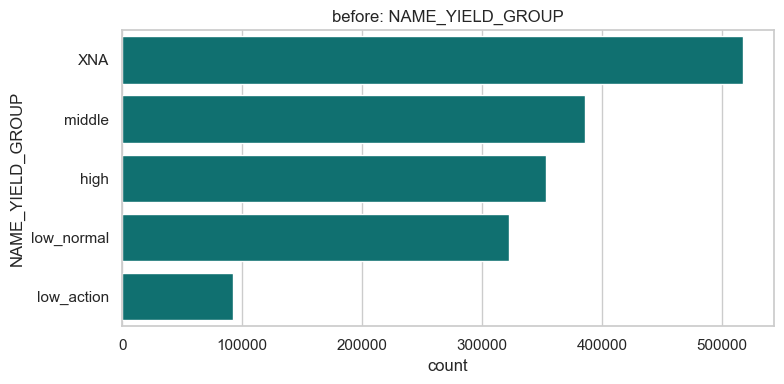

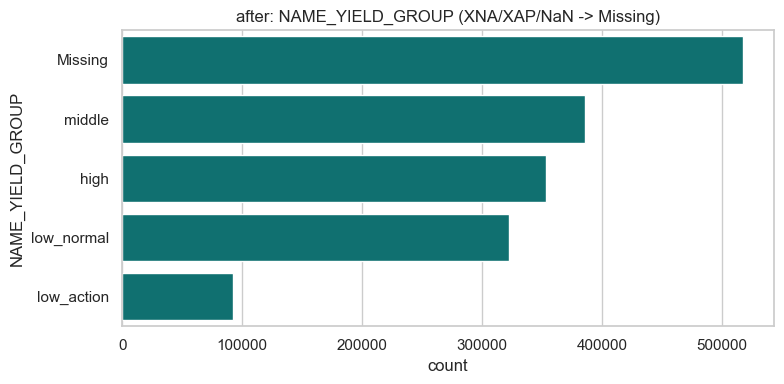

[decision] previous_application.NAME_YIELD_GROUP: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=517215 n_miss=0)

=== previous_application.PRODUCT_COMBINATION ===
dtype=object  missing=346 (0.02%)
n_unique=17


PRODUCT_COMBINATION
Cash                              285990
POS household with interest       263622
POS mobile with interest          220670
Cash X-Sell: middle               143883
Cash X-Sell: low                  130248
Card Street                       112582
POS industry with interest         98833
POS household without interest     82908
Card X-Sell                        80582
Cash Street: high                  59639
Cash X-Sell: high                  59301
Cash Street: middle                34658
Name: count, dtype: int64

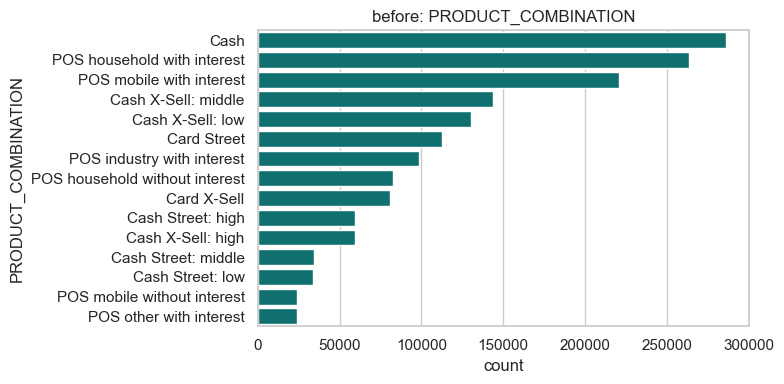

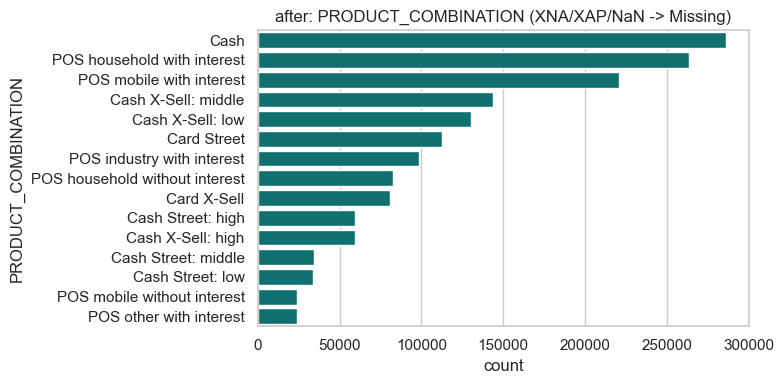

[decision] previous_application.PRODUCT_COMBINATION: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=0 n_miss=346)

=== previous_application.NAME_PAYMENT_TYPE ===
dtype=object  missing=0 (0.00%)
n_unique=4


NAME_PAYMENT_TYPE
Cash through the bank                        1033552
XNA                                           627384
Non-cash from your account                      8193
Cashless from the account of the employer       1085
Name: count, dtype: int64

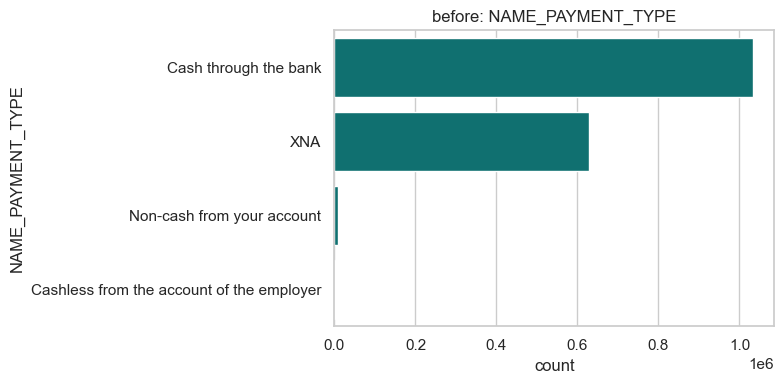

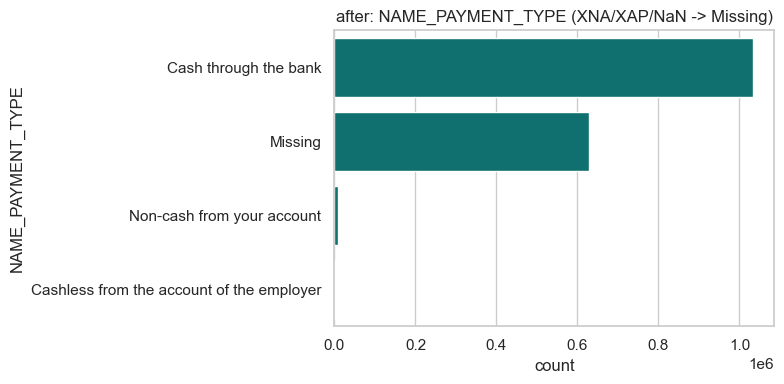

[decision] previous_application.NAME_PAYMENT_TYPE: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=627384 n_miss=0)

=== previous_application.NAME_TYPE_SUITE ===
dtype=object  missing=820,405 (49.12%)
n_unique=7


NAME_TYPE_SUITE
NaN                820405
Unaccompanied      508970
Family             213263
Spouse, partner     67069
Children            31566
Other_B             17624
Other_A              9077
Group of people      2240
Name: count, dtype: int64

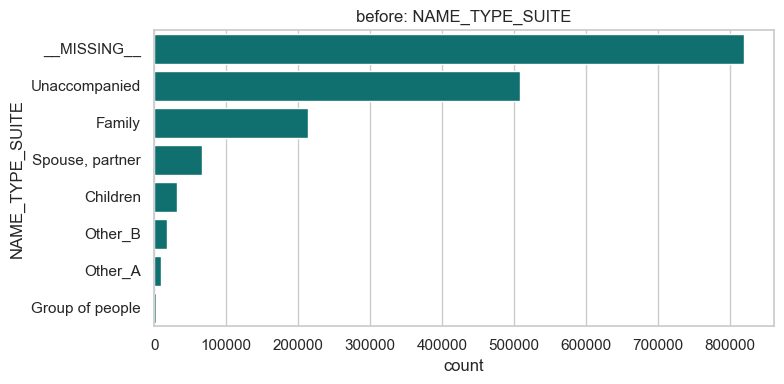

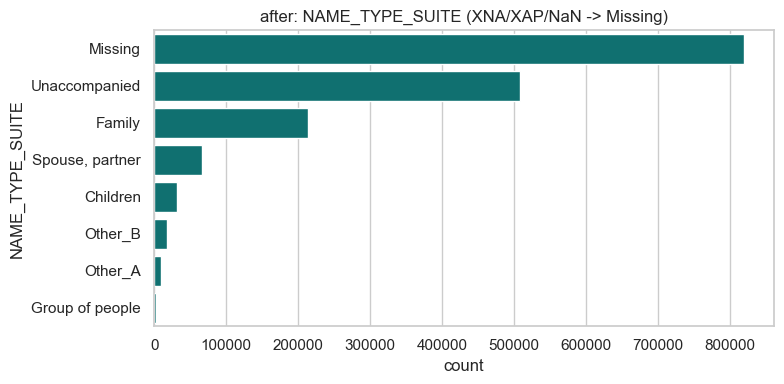

[decision] previous_application.NAME_TYPE_SUITE: map XNA/XAP/NaN -> Missing (XNA/XAP/NaN n_x=0 n_miss=820405)


In [24]:
cat_cols = [
    "NAME_CONTRACT_TYPE",
    "NAME_CASH_LOAN_PURPOSE",
    "CODE_REJECT_REASON",
    "NAME_CLIENT_TYPE",
    "NAME_GOODS_CATEGORY",
    "NAME_PORTFOLIO",
    "NAME_PRODUCT_TYPE",
    "CHANNEL_TYPE",
    "NAME_SELLER_INDUSTRY",
    "NAME_YIELD_GROUP",
    "PRODUCT_COMBINATION",
    "NAME_PAYMENT_TYPE",
    "NAME_TYPE_SUITE",
]

for col in cat_cols:
    if col not in prev.columns:
        continue
    feature_report(prev, col, "previous_application")
    plot_categorical(prev[col], f"before: {col}", top_n=15)

    before_n = prev[col].copy()
    n_x = int(before_n.isin(["XNA", "XAP"]).sum())
    n_miss = int(before_n.isna().sum())
    prev[col] = (
        before_n.replace({"XNA": "Missing", "XAP": "Missing"})
        .fillna("Missing")
    )
    plot_categorical(prev[col], f"after: {col} (XNA/XAP/NaN -> Missing)", top_n=15)
    record(
        "previous_application",
        col,
        f"XNA/XAP/NaN n_x={n_x} n_miss={n_miss}",
        "map XNA/XAP/NaN -> Missing",
    )

## Features: `RATE_DOWN_PAYMENT`, `RATE_INTEREST_*`, `CNT_PAYMENT`, `SELLERPLACE_AREA`


=== previous_application.RATE_DOWN_PAYMENT ===
dtype=float64  missing=895,844 (53.64%)
n_unique=207033


count    774370.000000
mean          0.079637
std           0.107823
min          -0.000015
25%           0.000000
50%           0.051605
75%           0.108909
max           1.000000
Name: RATE_DOWN_PAYMENT, dtype: float64

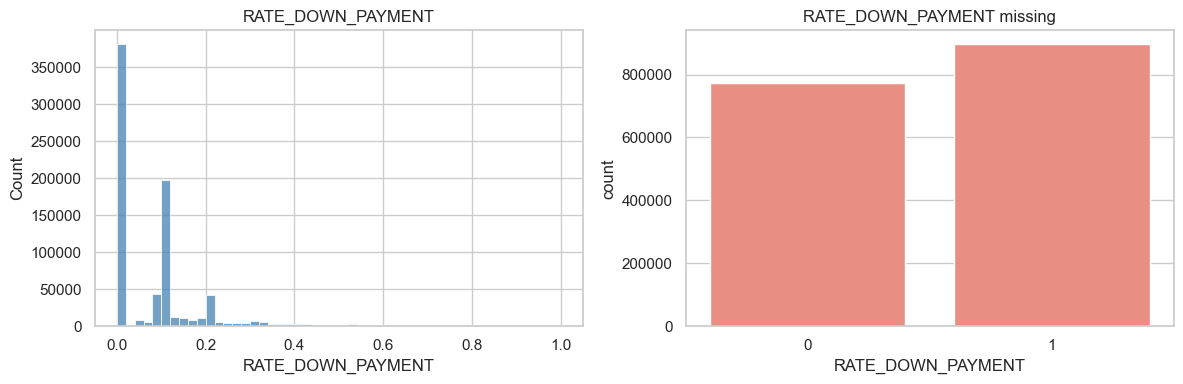

[decision] previous_application.RATE_DOWN_PAYMENT: keep NaN + RATE_DOWN_PAYMENT_MISSING (missing)

=== previous_application.RATE_INTEREST_PRIMARY ===
dtype=float64  missing=1,664,263 (99.64%)
n_unique=148


count    5951.000000
mean        0.188357
std         0.087671
min         0.034781
25%         0.160716
50%         0.189122
75%         0.193330
max         1.000000
Name: RATE_INTEREST_PRIMARY, dtype: float64

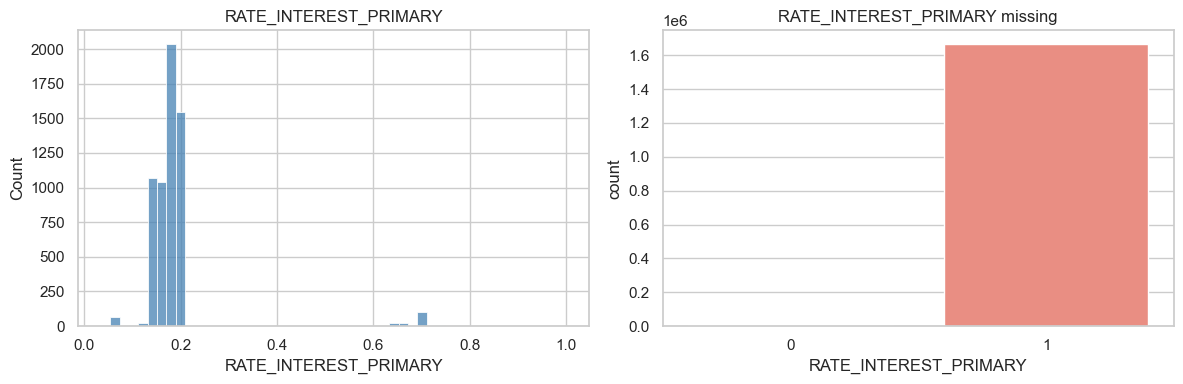

[decision] previous_application.RATE_INTEREST_PRIMARY: keep NaN + RATE_INTEREST_PRIMARY_MISSING (missing)

=== previous_application.RATE_INTEREST_PRIVILEGED ===
dtype=float64  missing=1,664,263 (99.64%)
n_unique=25


count    5951.000000
mean        0.773503
std         0.100879
min         0.373150
25%         0.715645
50%         0.835095
75%         0.852537
max         1.000000
Name: RATE_INTEREST_PRIVILEGED, dtype: float64

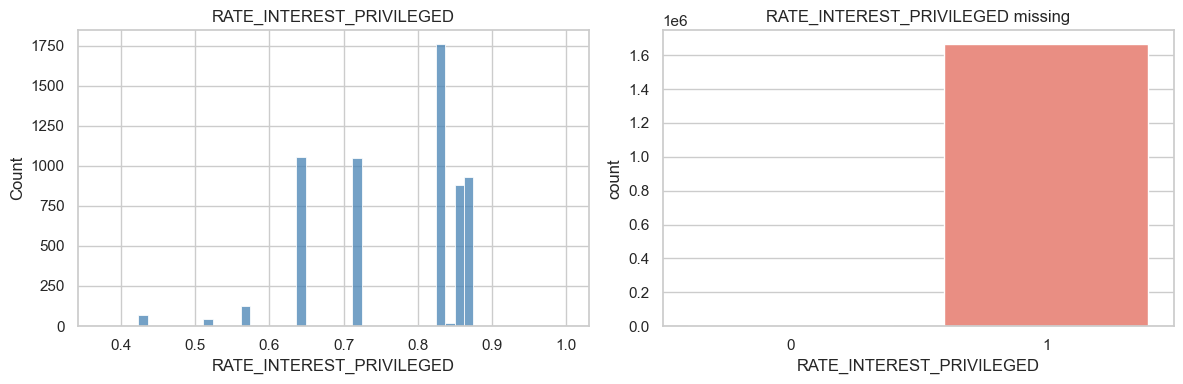

[decision] previous_application.RATE_INTEREST_PRIVILEGED: keep NaN + RATE_INTEREST_PRIVILEGED_MISSING (missing)

=== previous_application.CNT_PAYMENT ===
dtype=float64  missing=372,230 (22.29%)
n_unique=49


count    1.297984e+06
mean     1.605408e+01
std      1.456729e+01
min      0.000000e+00
25%      6.000000e+00
50%      1.200000e+01
75%      2.400000e+01
max      8.400000e+01
Name: CNT_PAYMENT, dtype: float64

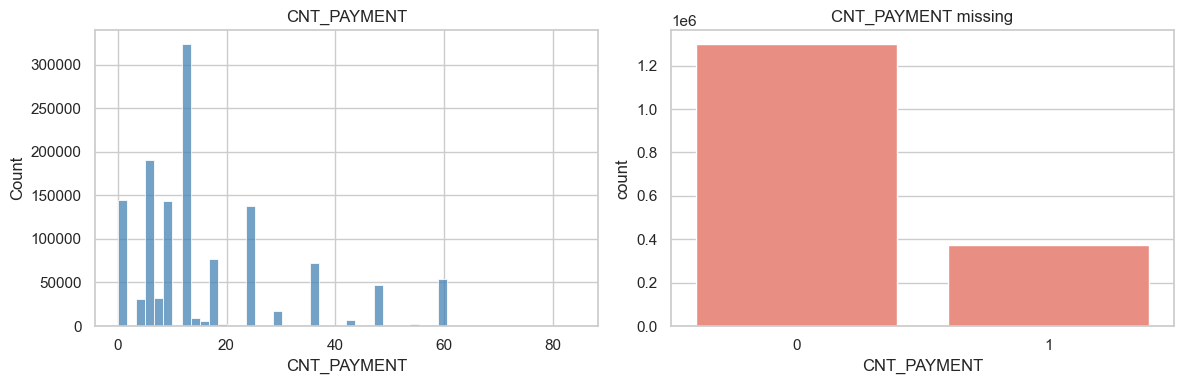

[decision] previous_application.CNT_PAYMENT: keep NaN + CNT_PAYMENT_MISSING (missing)

=== previous_application.SELLERPLACE_AREA ===
dtype=int64  missing=0 (0.00%)
n_unique=2097


count    1.670214e+06
mean     3.139511e+02
std      7.127443e+03
min     -1.000000e+00
25%     -1.000000e+00
50%      3.000000e+00
75%      8.200000e+01
max      4.000000e+06
Name: SELLERPLACE_AREA, dtype: float64

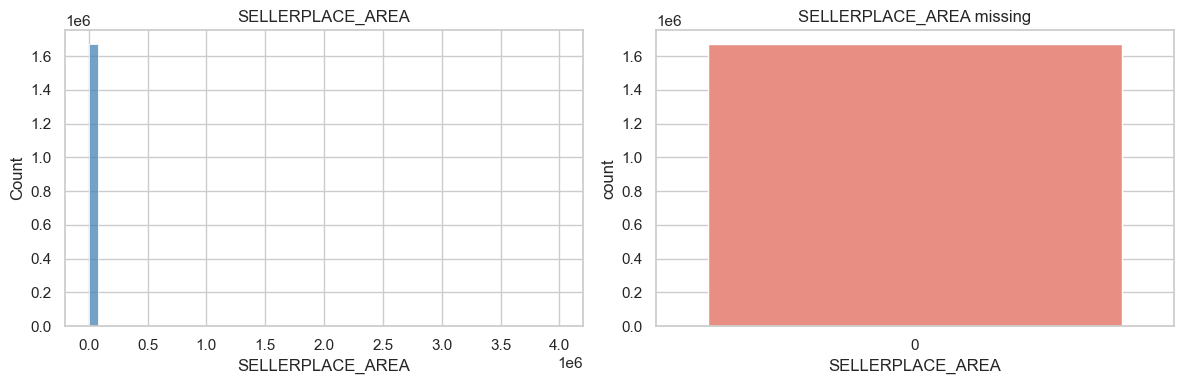

[decision] previous_application.SELLERPLACE_AREA: keep as-is (none)
SELLERPLACE_AREA == -1: 762675


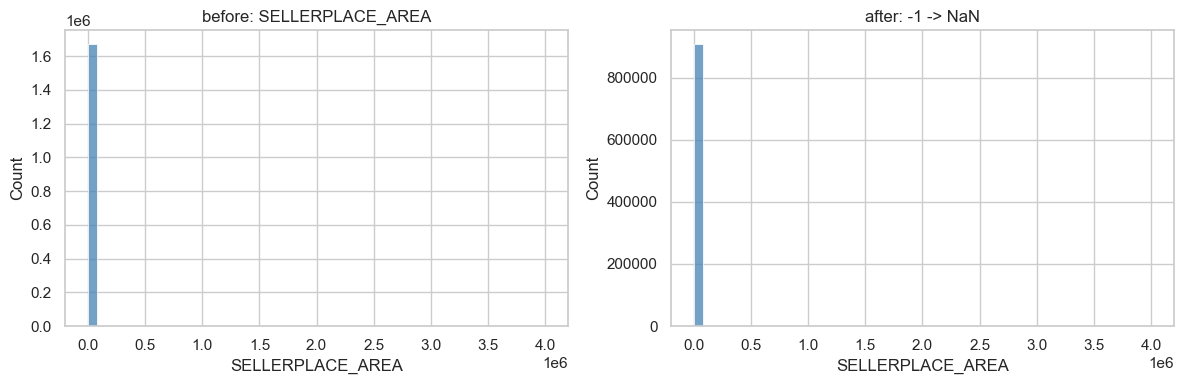

[decision] previous_application.SELLERPLACE_AREA: set -1 to NaN + missing flag (-1 unknown n=762675)


In [25]:
extra_num = [
    "RATE_DOWN_PAYMENT",
    "RATE_INTEREST_PRIMARY",
    "RATE_INTEREST_PRIVILEGED",
    "CNT_PAYMENT",
    "SELLERPLACE_AREA",
]
for col in extra_num:
    feature_report(prev, col, "previous_application")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    plot_numeric(prev[col], col, ax=axes[0])
    sns.countplot(x=prev[col].isna().astype(int), ax=axes[1], color="salmon")
    axes[1].set_title(f"{col} missing")
    plt.tight_layout()
    plt.show()
    if prev[col].isna().any():
        prev[f"{col}_MISSING"] = prev[col].isna().astype("int8")
        record("previous_application", col, "missing", f"keep NaN + {col}_MISSING")
    else:
        record("previous_application", col, "none", "keep as-is")

# SELLERPLACE_AREA uses -1 as unknown in Home Credit
if "SELLERPLACE_AREA" in prev.columns:
    n_m1 = int((prev["SELLERPLACE_AREA"] == -1).sum())
    print("SELLERPLACE_AREA == -1:", n_m1)
    before = prev["SELLERPLACE_AREA"].copy()
    prev.loc[prev["SELLERPLACE_AREA"] == -1, "SELLERPLACE_AREA"] = np.nan
    prev["SELLERPLACE_AREA_MISSING"] = prev["SELLERPLACE_AREA"].isna().astype("int8")
    before_after_numeric(
        before,
        prev["SELLERPLACE_AREA"],
        "before: SELLERPLACE_AREA",
        "after: -1 -> NaN",
    )
    record(
        "previous_application",
        "SELLERPLACE_AREA",
        f"-1 unknown n={n_m1}",
        "set -1 to NaN + missing flag",
    )

In [26]:
prev_out = PROCESSED_DATA_DIR / "previous_application_clean.parquet"
prev.to_parquet(prev_out, index=False)
print("wrote", prev_out, "shape", prev.shape)
del prev
gc.collect()

wrote C:\Users\user\Desktop\Credit-Scoring Project\data\processed\previous_application_clean.parquet shape (1670214, 51)


50846

---
# D. `installments_payments.csv`

Repayment behaviour (closest analogue to mobile-money repayment history).
Large file: sample plots + chunked cleaning rules / stats.

file_mb: 689.6
DAYS_INSTALMENT {'rows': 13605401, 'null': 0, 'sentinel': 0}
DAYS_ENTRY_PAYMENT {'rows': 13605401, 'null': 2905, 'sentinel': 0}
AMT_INSTALMENT {'rows': 13605401, 'null': 0, 'sentinel': 0}
AMT_PAYMENT {'rows': 13605401, 'null': 2905, 'sentinel': 0}
sample shape: (80000, 8)

=== installments(sample).DAYS_ENTRY_PAYMENT ===
dtype=float64  missing=0 (0.00%)
n_unique=2949


count    80000.000000
mean     -1054.650250
std        802.796854
min      -3026.000000
25%      -1668.000000
50%       -831.000000
75%       -372.000000
max         -2.000000
Name: DAYS_ENTRY_PAYMENT, dtype: float64


=== installments(sample).DAYS_INSTALMENT ===
dtype=float64  missing=0 (0.00%)
n_unique=2921


count    80000.000000
mean     -1045.792950
std        803.228529
min      -2922.000000
25%      -1661.000000
50%       -821.000000
75%       -363.000000
max         -2.000000
Name: DAYS_INSTALMENT, dtype: float64

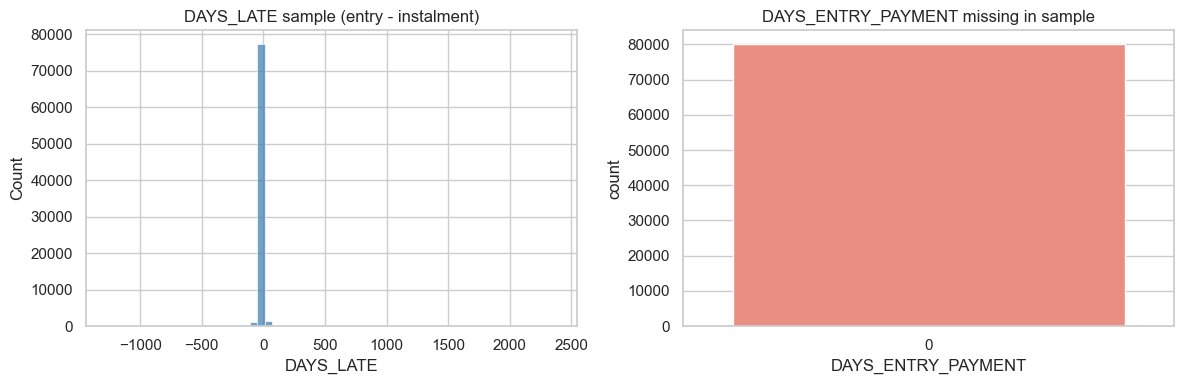

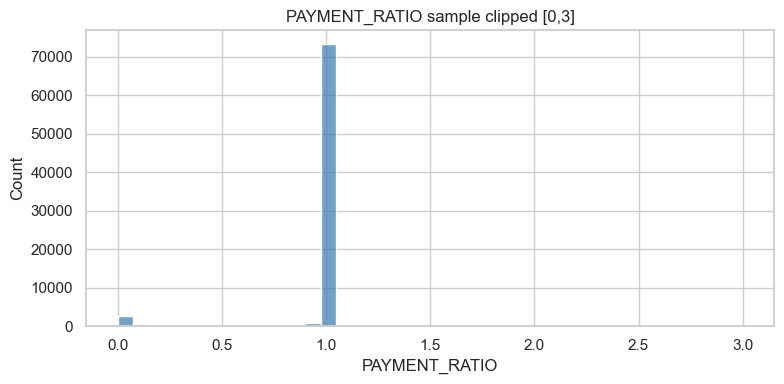

DAYS_INSTALMENT > 0 in sample: 0
DAYS_ENTRY_PAYMENT > 0 in sample: 0
[decision] installments_payments.DAYS_ENTRY_PAYMENT: keep NaN; derive late/underpay features only when both day fields present (missing when payment timing unknown)
[decision] installments_payments.DAYS_INSTALMENT: keep; use only offsets available at application time in SQL (relative offset)
[decision] installments_payments.AMT_PAYMENT/AMT_INSTALMENT: derive payment ratio / late flags in feature SQL (under/over payment)
[decision] installments_payments.table: no full parquet rewrite; cleaning applied in DuckDB SQL (very large)


39467

In [27]:
inst_path = RAW_DATA_DIR / "installments_payments.csv"
print("file_mb:", round(inst_path.stat().st_size / 1024**2, 1))

for col in ["DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"]:
    stats = chunked_null_and_sentinel(inst_path, col)
    print(col, stats)

inst = sample_csv(inst_path, n=SAMPLE_N)
print("sample shape:", inst.shape)

# DAYS_ENTRY_PAYMENT missing => payment not recorded / unpaid timing unknown
feature_report(inst, "DAYS_ENTRY_PAYMENT", "installments(sample)")
feature_report(inst, "DAYS_INSTALMENT", "installments(sample)")

inst["DAYS_LATE"] = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_numeric(inst["DAYS_LATE"], "DAYS_LATE sample (entry - instalment)", bins=60, ax=axes[0])
sns.countplot(x=inst["DAYS_ENTRY_PAYMENT"].isna().astype(int), ax=axes[1], color="salmon")
axes[1].set_title("DAYS_ENTRY_PAYMENT missing in sample")
plt.tight_layout()
plt.show()

inst["PAYMENT_RATIO"] = inst["AMT_PAYMENT"] / inst["AMT_INSTALMENT"].replace(0, np.nan)
fig, ax = plt.subplots(figsize=(8, 4))
plot_numeric(
    inst["PAYMENT_RATIO"].clip(0, 3),
    "PAYMENT_RATIO sample clipped [0,3]",
    bins=40,
    ax=ax,
)
plt.tight_layout()
plt.show()

print("DAYS_INSTALMENT > 0 in sample:", int((inst["DAYS_INSTALMENT"] > 0).sum()))
print("DAYS_ENTRY_PAYMENT > 0 in sample:", int((inst["DAYS_ENTRY_PAYMENT"] > 0).sum()))

record(
    "installments_payments",
    "DAYS_ENTRY_PAYMENT",
    "missing when payment timing unknown",
    "keep NaN; derive late/underpay features only when both day fields present",
)
record(
    "installments_payments",
    "DAYS_INSTALMENT",
    "relative offset",
    "keep; use only offsets available at application time in SQL",
)
record(
    "installments_payments",
    "AMT_PAYMENT/AMT_INSTALMENT",
    "under/over payment",
    "derive payment ratio / late flags in feature SQL",
)
record(
    "installments_payments",
    "table",
    "very large",
    "no full parquet rewrite; cleaning applied in DuckDB SQL",
)

del inst
gc.collect()

---
# E. `POS_CASH_balance.csv`

file_mb: 374.5


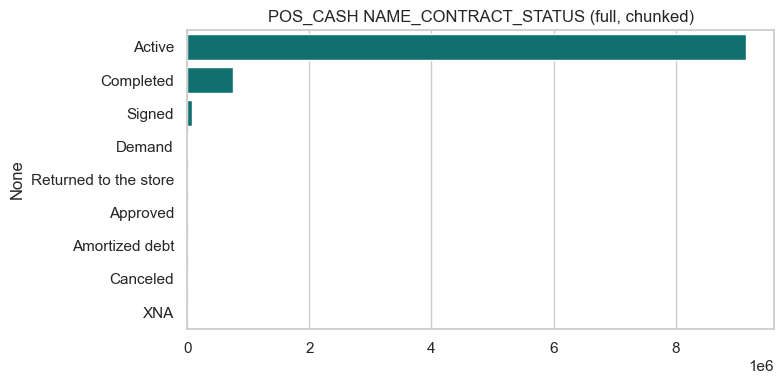


=== POS_CASH(sample).MONTHS_BALANCE ===
dtype=int64  missing=0 (0.00%)
n_unique=96


count    80000.000000
mean       -27.186563
std         23.811951
min        -96.000000
25%        -40.000000
50%        -18.000000
75%        -10.000000
max         -1.000000
Name: MONTHS_BALANCE, dtype: float64

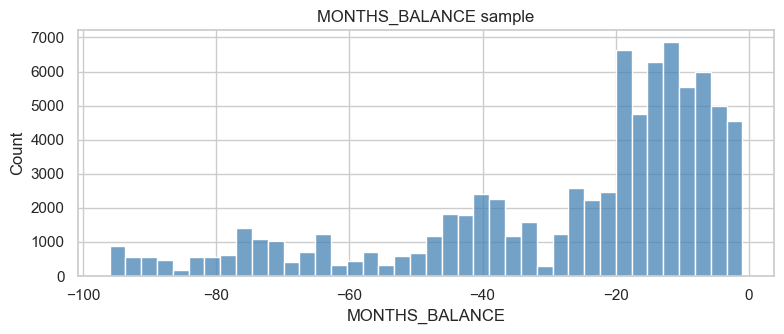


=== POS_CASH(sample).CNT_INSTALMENT ===
dtype=float64  missing=137 (0.17%)
n_unique=53


count    79863.000000
mean        20.462304
std         14.091237
min          1.000000
25%         10.000000
50%         14.000000
75%         24.000000
max         72.000000
Name: CNT_INSTALMENT, dtype: float64

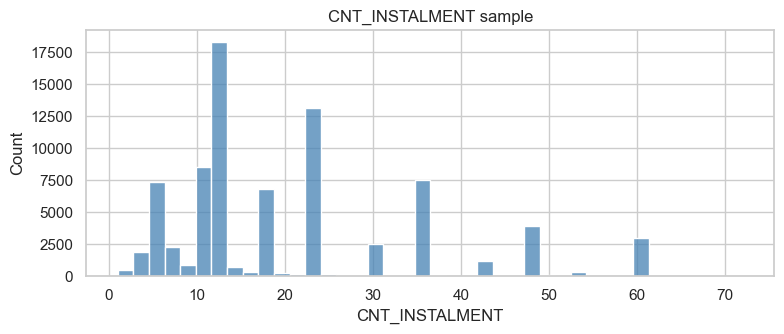


=== POS_CASH(sample).CNT_INSTALMENT_FUTURE ===
dtype=float64  missing=137 (0.17%)
n_unique=64


count    79863.000000
mean        13.054769
std         12.924356
min          0.000000
25%          4.000000
50%          9.000000
75%         18.000000
max         66.000000
Name: CNT_INSTALMENT_FUTURE, dtype: float64

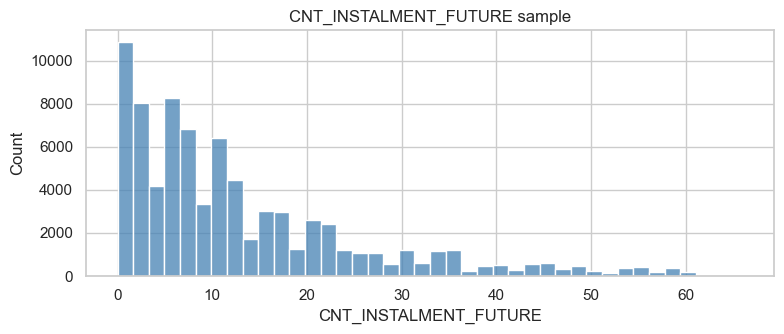


=== POS_CASH(sample).SK_DPD ===
dtype=int64  missing=0 (0.00%)
n_unique=108


count    80000.000000
mean         0.395363
std         16.784073
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       2205.000000
Name: SK_DPD, dtype: float64

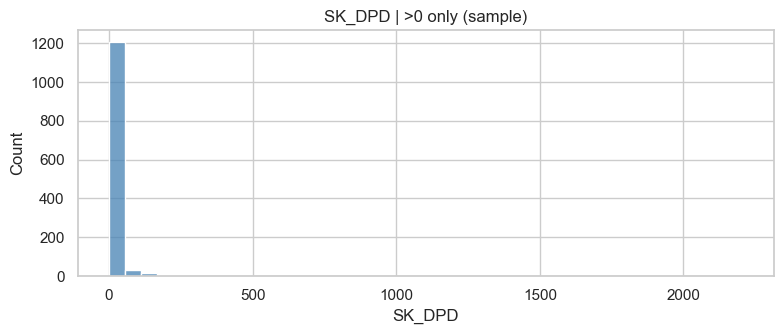


=== POS_CASH(sample).SK_DPD_DEF ===
dtype=int64  missing=0 (0.00%)
n_unique=39


count    80000.000000
mean         0.064825
std          1.296792
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        203.000000
Name: SK_DPD_DEF, dtype: float64

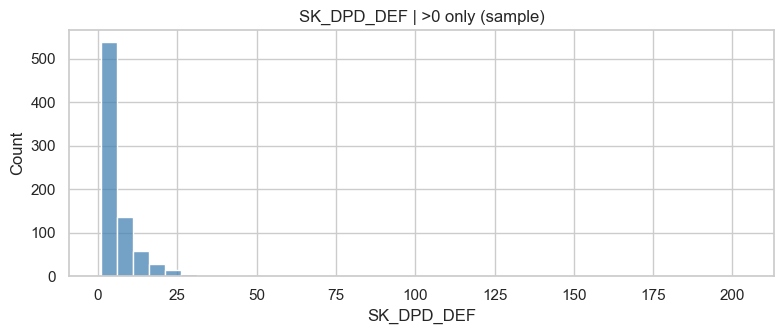

MONTHS_BALANCE > 0: 0
CNT_INSTALMENT null/sentinel stats {'rows': 10001358, 'null': 26071, 'sentinel': 0}
CNT_INSTALMENT_FUTURE null/sentinel stats {'rows': 10001358, 'null': 26087, 'sentinel': 0}
[decision] POS_CASH_balance.MONTHS_BALANCE: use only <= 0 (relative month)
[decision] POS_CASH_balance.SK_DPD/SK_DPD_DEF: keep; aggregate in SQL (delinquency days)
[decision] POS_CASH_balance.CNT_INSTALMENT*: keep NaN; impute/aggregate carefully in SQL (some missing)
[decision] POS_CASH_balance.table: rules in SQL; no full rewrite here (large)


16926

In [28]:
pos_path = RAW_DATA_DIR / "POS_CASH_balance.csv"
print("file_mb:", round(pos_path.stat().st_size / 1024**2, 1))

pos_status = chunked_value_counts(pos_path, "NAME_CONTRACT_STATUS", top_n=15)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=pos_status.values, y=pos_status.index.astype(str), ax=ax, color="teal")
ax.set_title("POS_CASH NAME_CONTRACT_STATUS (full, chunked)")
plt.tight_layout()
plt.show()

pos = sample_csv(pos_path, n=SAMPLE_N)
for col in ["MONTHS_BALANCE", "CNT_INSTALMENT", "CNT_INSTALMENT_FUTURE", "SK_DPD", "SK_DPD_DEF"]:
    feature_report(pos, col, "POS_CASH(sample)")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    if col.startswith("SK_DPD"):
        plot_numeric(pos.loc[pos[col] > 0, col], f"{col} | >0 only (sample)", bins=40, ax=ax)
    else:
        plot_numeric(pos[col], f"{col} sample", bins=40, ax=ax)
    plt.tight_layout()
    plt.show()

print("MONTHS_BALANCE > 0:", int((pos["MONTHS_BALANCE"] > 0).sum()))

for col in ["CNT_INSTALMENT", "CNT_INSTALMENT_FUTURE"]:
    stats = chunked_null_and_sentinel(pos_path, col)
    print(col, "null/sentinel stats", stats)

record("POS_CASH_balance", "MONTHS_BALANCE", "relative month", "use only <= 0")
record("POS_CASH_balance", "SK_DPD/SK_DPD_DEF", "delinquency days", "keep; aggregate in SQL")
record(
    "POS_CASH_balance",
    "CNT_INSTALMENT*",
    "some missing",
    "keep NaN; impute/aggregate carefully in SQL",
)
record("POS_CASH_balance", "table", "large", "rules in SQL; no full rewrite here")

del pos
gc.collect()

---
# F. `credit_card_balance.csv`

Note: source column `AMT_RECIVABLE` is a misspelling in the dataset; keep name for join compatibility.

file_mb: 404.9
sample shape: (80000, 23)


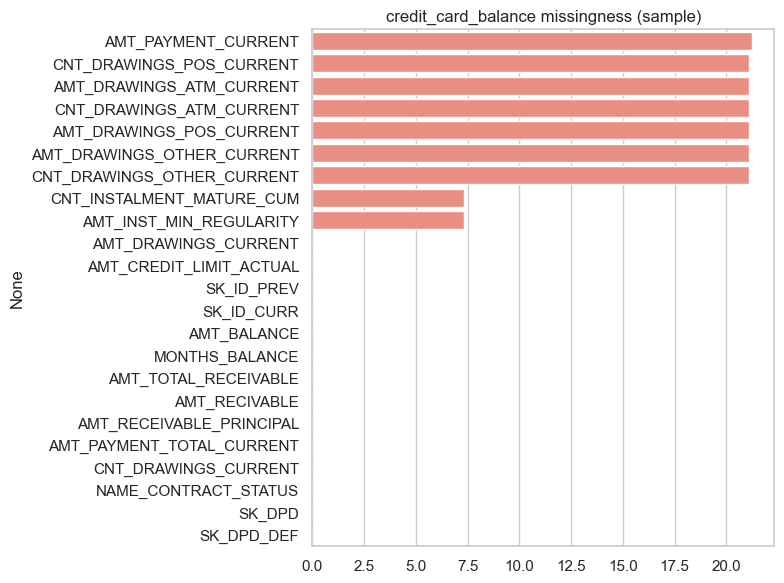


=== credit_card(sample).MONTHS_BALANCE ===
dtype=int64  missing=0 (0.00%)
n_unique=96


count    80000.000000
mean       -34.281850
std         27.722242
min        -96.000000
25%        -57.000000
50%        -26.000000
75%        -10.000000
max         -1.000000
Name: MONTHS_BALANCE, dtype: float64

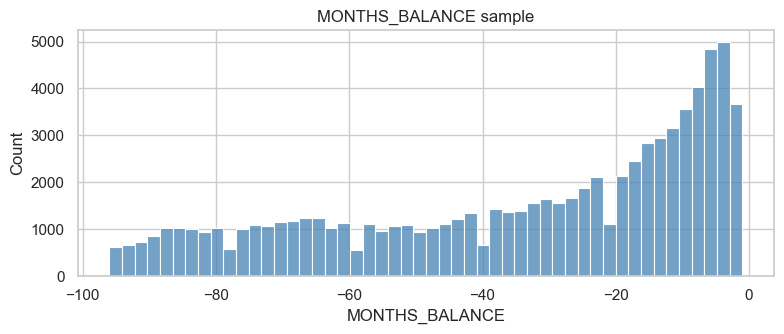


=== credit_card(sample).AMT_BALANCE ===
dtype=float64  missing=0 (0.00%)
n_unique=32479


count     80000.000000
mean      54203.422141
std       99526.958897
min     -261471.015000
25%           0.000000
50%           0.000000
75%       83743.740000
max      942903.630000
Name: AMT_BALANCE, dtype: float64

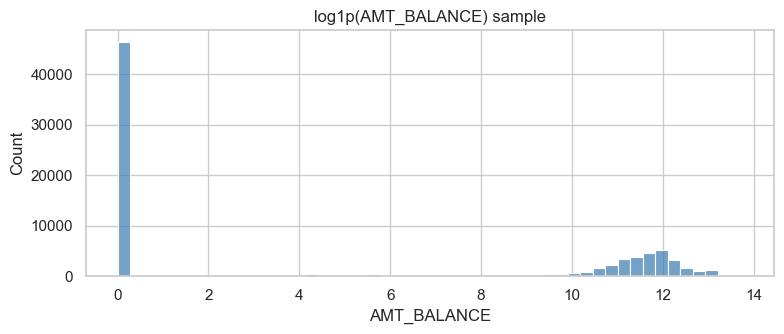


=== credit_card(sample).AMT_CREDIT_LIMIT_ACTUAL ===
dtype=int64  missing=0 (0.00%)
n_unique=110


count    8.000000e+04
mean     1.505854e+05
std      1.611219e+05
min      0.000000e+00
25%      4.500000e+04
50%      1.125000e+05
75%      1.800000e+05
max      1.350000e+06
Name: AMT_CREDIT_LIMIT_ACTUAL, dtype: float64

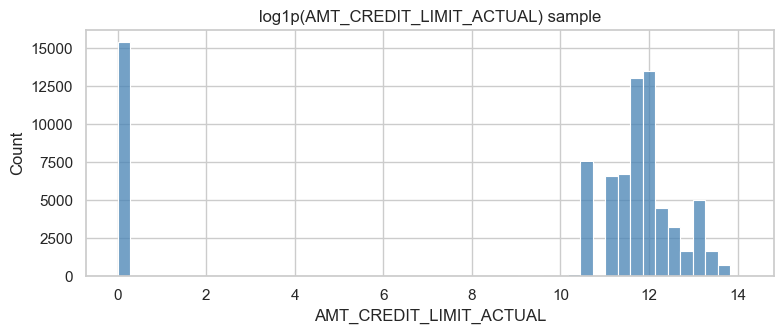


=== credit_card(sample).AMT_DRAWINGS_CURRENT ===
dtype=float64  missing=0 (0.00%)
n_unique=4651


count     80000.000000
mean       6347.208585
std       30148.957406
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max      963346.500000
Name: AMT_DRAWINGS_CURRENT, dtype: float64

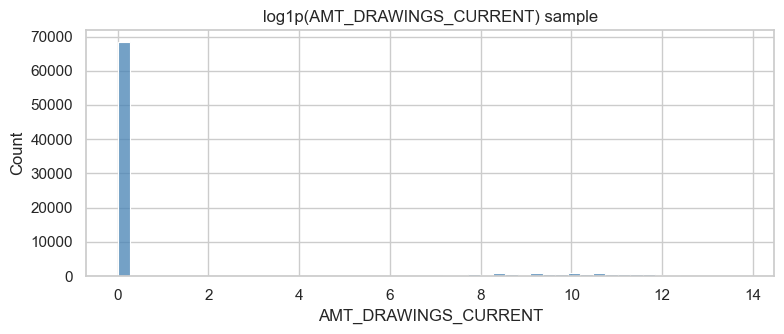


=== credit_card(sample).AMT_PAYMENT_TOTAL_CURRENT ===
dtype=float64  missing=0 (0.00%)
n_unique=7375


count    8.000000e+04
mean     7.212654e+03
std      3.152323e+04
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      6.750000e+03
max      1.049659e+06
Name: AMT_PAYMENT_TOTAL_CURRENT, dtype: float64

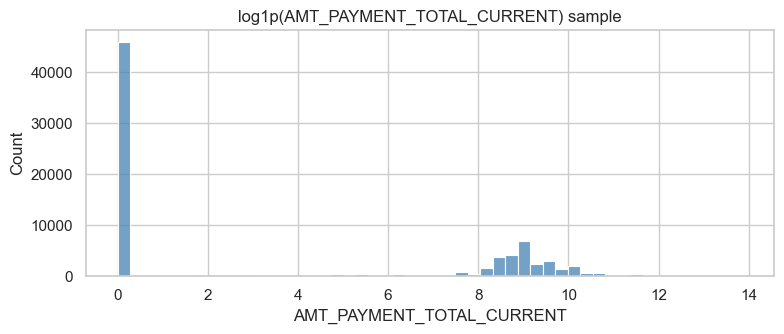


=== credit_card(sample).SK_DPD ===
dtype=int64  missing=0 (0.00%)
n_unique=294


count    80000.000000
mean         9.136638
std         97.475488
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       2833.000000
Name: SK_DPD, dtype: float64

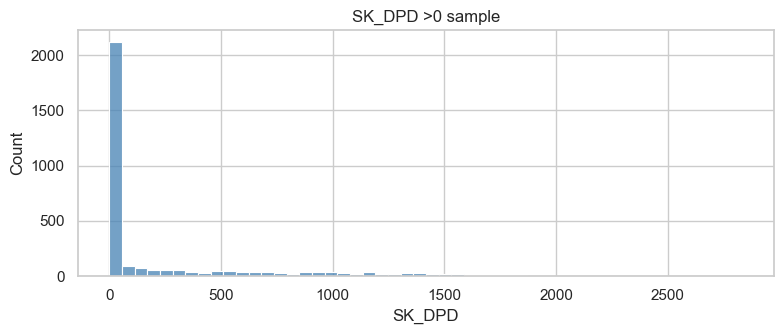


=== credit_card(sample).SK_DPD_DEF ===
dtype=int64  missing=0 (0.00%)
n_unique=40


count    80000.000000
mean         0.334637
std         22.661201
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       2833.000000
Name: SK_DPD_DEF, dtype: float64

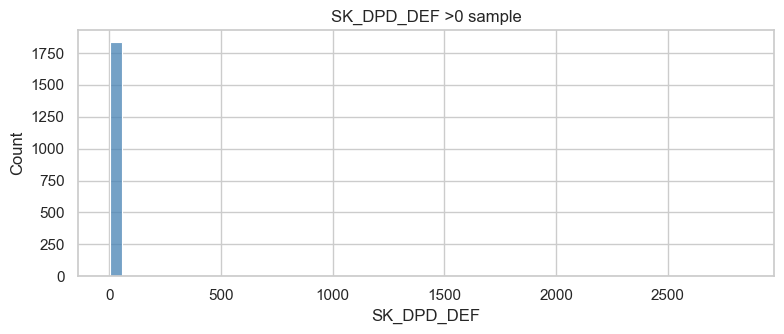

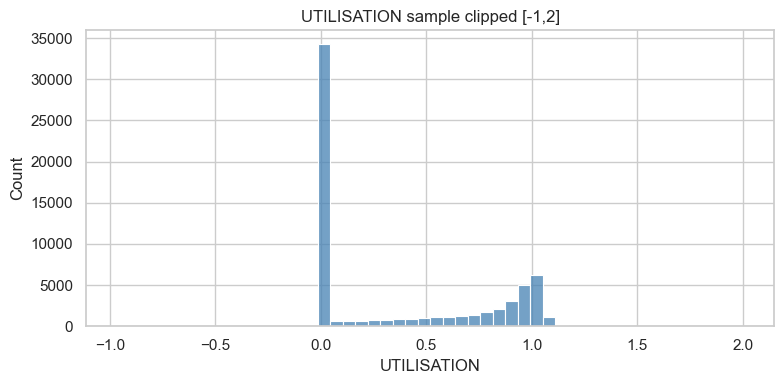

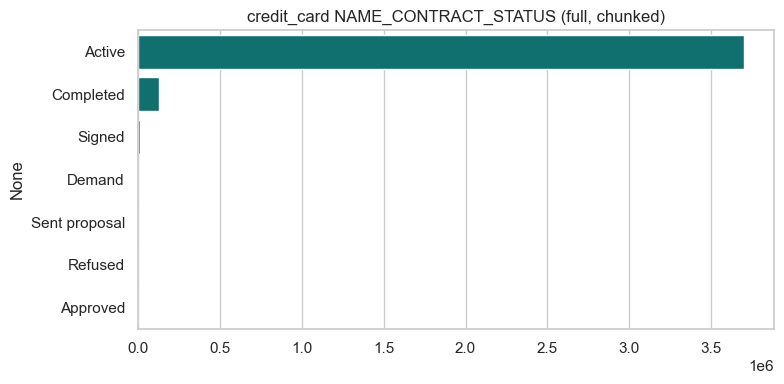

[decision] credit_card_balance.AMT_RECIVABLE: keep original column name (dataset typo in name)
[decision] credit_card_balance.drawings/payment fields: keep NaN; aggregate in SQL (block missingness)
[decision] credit_card_balance.MONTHS_BALANCE: use only <= 0 (relative month)
[decision] credit_card_balance.utilisation: safe-divide in SQL (limit can be 0)
[decision] credit_card_balance.table: rules in SQL; no full rewrite here (large)


24984

In [29]:
cc_path = RAW_DATA_DIR / "credit_card_balance.csv"
print("file_mb:", round(cc_path.stat().st_size / 1024**2, 1))

cc = sample_csv(cc_path, n=SAMPLE_N)
print("sample shape:", cc.shape)
miss = (cc.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=miss.values, y=miss.index, ax=ax, color="salmon")
ax.set_title("credit_card_balance missingness (sample)")
plt.tight_layout()
plt.show()

for col in [
    "MONTHS_BALANCE",
    "AMT_BALANCE",
    "AMT_CREDIT_LIMIT_ACTUAL",
    "AMT_DRAWINGS_CURRENT",
    "AMT_PAYMENT_TOTAL_CURRENT",
    "SK_DPD",
    "SK_DPD_DEF",
]:
    feature_report(cc, col, "credit_card(sample)")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    if col.startswith("AMT_"):
        plot_numeric(np.log1p(cc[col].clip(lower=0)), f"log1p({col}) sample", ax=ax)
    elif col.startswith("SK_DPD"):
        plot_numeric(cc.loc[cc[col] > 0, col], f"{col} >0 sample", ax=ax)
    else:
        plot_numeric(cc[col], f"{col} sample", ax=ax)
    plt.tight_layout()
    plt.show()

# Utilisation proxy on sample
cc["UTILISATION"] = cc["AMT_BALANCE"] / cc["AMT_CREDIT_LIMIT_ACTUAL"].replace(0, np.nan)
fig, ax = plt.subplots(figsize=(8, 4))
plot_numeric(cc["UTILISATION"].clip(-1, 2), "UTILISATION sample clipped [-1,2]", ax=ax)
plt.tight_layout()
plt.show()

cc_status = chunked_value_counts(cc_path, "NAME_CONTRACT_STATUS", top_n=10)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=cc_status.values, y=cc_status.index.astype(str), ax=ax, color="teal")
ax.set_title("credit_card NAME_CONTRACT_STATUS (full, chunked)")
plt.tight_layout()
plt.show()

record("credit_card_balance", "AMT_RECIVABLE", "dataset typo in name", "keep original column name")
record("credit_card_balance", "drawings/payment fields", "block missingness", "keep NaN; aggregate in SQL")
record("credit_card_balance", "MONTHS_BALANCE", "relative month", "use only <= 0")
record("credit_card_balance", "utilisation", "limit can be 0", "safe-divide in SQL")
record("credit_card_balance", "table", "large", "rules in SQL; no full rewrite here")

del cc
gc.collect()

---
# Save decision log

In [30]:
out_decisions = PROCESSED_DATA_DIR / "child_tables_cleaning_decisions.json"
payload = {
    "day_sentinel": int(DAY_SENTINEL),
    "cleaned_parquets": [
        "bureau_clean.parquet",
        "previous_application_clean.parquet",
    ],
    "sql_only_tables": [
        "bureau_balance.csv",
        "installments_payments.csv",
        "POS_CASH_balance.csv",
        "credit_card_balance.csv",
    ],
    "decisions": DECISIONS,
}
out_decisions.write_text(json.dumps(payload, indent=2), encoding="ascii", errors="replace")

print("wrote", out_decisions)
print("n decisions:", len(DECISIONS))
decisions_df = pd.DataFrame(DECISIONS)
display(decisions_df.groupby("table").size().rename("n_decisions"))
display(decisions_df.tail(25))

wrote C:\Users\user\Desktop\Credit-Scoring Project\data\processed\child_tables_cleaning_decisions.json
n decisions: 64


table
POS_CASH_balance          4
bureau                   17
bureau_balance            3
credit_card_balance       5
installments_payments     4
previous_application     31
Name: n_decisions, dtype: int64

,table,feature,issue,action,detail
39,previous_application,CHANNEL_TYPE,XNA/XAP/NaN n_x=0 n_miss=0,map XNA/XAP/NaN -> Missing,
40,previous_application,NAME_SELLER_INDUSTRY,XNA/XAP/NaN n_x=855720 n_miss=0,map XNA/XAP/NaN -> Missing,
41,previous_application,NAME_YIELD_GROUP,XNA/XAP/NaN n_x=517215 n_miss=0,map XNA/XAP/NaN -> Missing,
42,previous_application,PRODUCT_COMBINATION,XNA/XAP/NaN n_x=0 n_miss=346,map XNA/XAP/NaN -> Missing,
43,previous_application,NAME_PAYMENT_TYPE,XNA/XAP/NaN n_x=627384 n_miss=0,map XNA/XAP/NaN -> Missing,
44,previous_application,NAME_TYPE_SUITE,XNA/XAP/NaN n_x=0 n_miss=820405,map XNA/XAP/NaN -> Missing,
45,previous_application,RATE_DOWN_PAYMENT,missing,keep NaN + RATE_DOWN_PAYMENT_MISSING,
46,previous_application,RATE_INTEREST_PRIMARY,missing,keep NaN + RATE_INTEREST_PRIMARY_MISSING,
47,previous_application,RATE_INTEREST_PRIVILEGED,missing,keep NaN + RATE_INTEREST_PRIVILEGED_MISSING,
48,previous_application,CNT_PAYMENT,missing,keep NaN + CNT_PAYMENT_MISSING,


## Summary

| Table | Handling |
|---|---|
| `bureau` | Cleaned parquet; positive `DAYS_CREDIT_UPDATE` nulled; missing flags |
| `previous_application` | Cleaned parquet; `365243` day sentinels nulled; XNA/XAP -> Missing |
| `bureau_balance` | Rules only (large); STATUS / MONTHS_BALANCE checked |
| `installments_payments` | Rules only; late/payment-ratio logic for SQL |
| `POS_CASH_balance` | Rules only; DPD + months balance |
| `credit_card_balance` | Rules only; utilisation safe-divide |

Outputs:
- `data/processed/bureau_clean.parquet`
- `data/processed/previous_application_clean.parquet`
- `data/processed/child_tables_cleaning_decisions.json`

Next (after this looks good): port Stage 2 into `src/data_quality.py` + report, then **switch to premium** for Stage 3 SQL features.